In [ ]:
!apt-get install -y ffmpeg

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
ffmpeg is already the newest version (7:4.4.2-0ubuntu0.22.04.1).
0 upgraded, 0 newly installed, 0 to remove and 30 not upgraded.


=== Robot Kinematics Simulator ===
Select Main Mode:
  [F]orward Kinematics
  [I]nverse Kinematics
  [T]est
Enter F, I, or T: 40,4,6
Invalid choice. Please enter 'F', 'I' or 'T'.
Enter F, I, or T: f,i,t
Invalid choice. Please enter 'F', 'I' or 'T'.
Enter F, I, or T: f
Enter number of DOF (e.g., 2, 3, 6): 6

=== Forward Kinematics Mode ===
Select FK Method:
  [1] DH Parameters
  [2] Direct Method
  [3] Planar Method (2D)
Enter method (1-3): 1

Enter DH parameters for 6 joints (alpha, a, d, theta_offset in radians/meters):
Joint 1 [alpha a d theta_offset]: a
Invalid input. Please enter four numbers separated by spaces.
Joint 1 [alpha a d theta_offset]: 2,5,4,7
Invalid input. Please enter four numbers separated by spaces.
Joint 1 [alpha a d theta_offset]: 2 4 5 6 
Joint 2 [alpha a d theta_offset]: 4 5 6 7 
Joint 3 [alpha a d theta_offset]: 4 5 5 6
Joint 4 [alpha a d theta_offset]: 3 5 6 7 
Joint 5 [alpha a d theta_offset]: 2 4 5 6 
Joint 6 [alpha a d theta_offset]: 2 3 4 7
Enter 6 joint a

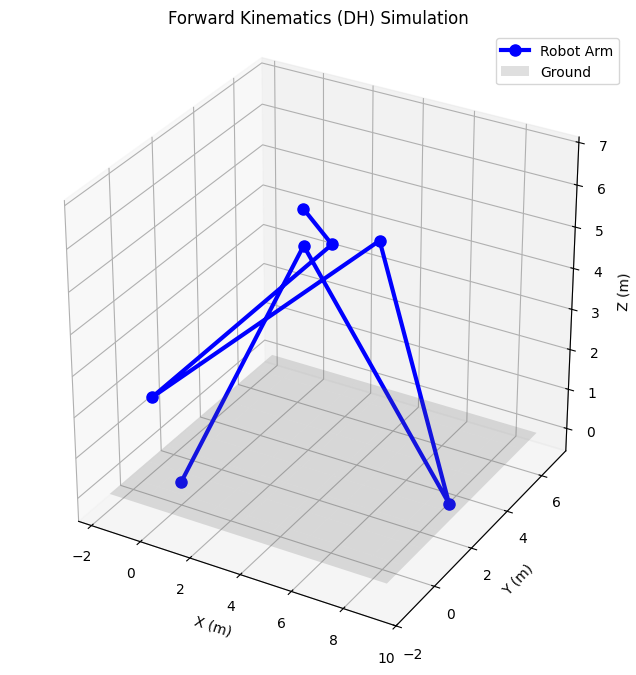

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# --- RobotArm Class ---
class RobotArm:
    def __init__(self, dof, link_lengths=None, dh_params=None, joint_limits=None):
        self.dof = dof
        self.link_lengths = link_lengths if link_lengths is not None else [0] * dof
        self.dh_params = dh_params if dh_params is not None else [[0, 0, 0, 0]] * dof
        self.joint_limits = joint_limits if joint_limits is not None else [(-np.pi, np.pi)] * dof

    def clamp_angles(self, angles):
        return [np.clip(a, self.joint_limits[i][0], self.joint_limits[i][1]) for i, a in enumerate(angles)]

    def dh_transform(self, alpha, a, d, theta):
        T = np.array([
            [np.cos(theta), -np.sin(theta)*np.cos(alpha),  np.sin(theta)*np.sin(alpha), a*np.cos(theta)],
            [np.sin(theta),  np.cos(theta)*np.cos(alpha), -np.cos(theta)*np.sin(alpha), a*np.sin(theta)],
            [0,             np.sin(alpha),                np.cos(alpha),               d],
            [0,             0,                           0,                          1]
        ])
        return T

    def forward_kinematics_dh(self, joint_angles):
        print("\n=== Forward Kinematics Calculation ===")
        T = np.eye(4)
        pos_list = [T[:3, 3].copy()]
        print("Initial Base Frame:\n", np.round(T, decimals=3))

        for i, (alpha, a, d, theta_offset) in enumerate(self.dh_params):
            theta = joint_angles[i] + theta_offset
            print(f"\nJoint {i+1}:")
            print(f"  Parameters: alpha={alpha:.3f}, a={a:.3f}, d={d:.3f}, theta={theta:.3f}")
            T_i = self.dh_transform(alpha, a, d, theta)
            print(f"  Transformation Matrix T{i+1}:\n", np.round(T_i, decimals=3))
            T = np.dot(T, T_i)
            print(f"  Cumulative Transformation after Joint {i+1}:\n", np.round(T, decimals=3))
            pos_list.append(T[:3, 3].copy())

        print("\nFinal End-Effector Pose:\n", np.round(T, decimals=3))
        return T, np.array(pos_list)

    def forward_kinematics_direct(self, joint_angles):
        print("\n=== Forward Kinematics using Direct Method ===")
        T = np.eye(4)
        pos_list = [T[:3, 3].copy()]
        print("Initial Base Frame:\n", np.round(T, decimals=3))

        for i in range(self.dof):
            theta = joint_angles[i]
            a = self.link_lengths[i]
            print(f"\nJoint {i+1}:")
            print(f"  Parameters: theta={theta:.3f}, link_length={a:.3f}")
            R_z = np.array([
                [np.cos(theta), -np.sin(theta), 0, 0],
                [np.sin(theta), np.cos(theta), 0, 0],
                [0, 0, 1, 0],
                [0, 0, 0, 1]
            ])
            T_x = np.array([
                [1, 0, 0, a],
                [0, 1, 0, 0],
                [0, 0, 1, 0],
                [0, 0, 0, 1]
            ])
            T_i = np.dot(R_z, T_x)
            print(f"  Transformation Matrix T{i+1}:\n", np.round(T_i, decimals=3))
            T = np.dot(T, T_i)
            print(f"  Cumulative Transformation after Joint {i+1}:\n", np.round(T, decimals=3))
            pos_list.append(T[:3, 3].copy())

        print("\nFinal End-Effector Pose:\n", np.round(T, decimals=3))
        return T, np.array(pos_list)

    def forward_kinematics_planar(self, joint_angles):
        print("\n=== Planar (2D) Forward Kinematics Calculation ===")
        x, y = 0, 0
        pos_x = [x]
        pos_y = [y]
        pos_list = [[x, y, 0]]
        cum_angle = 0
        print("Initial Position: x=0.000, y=0.000")

        for i, (length, angle) in enumerate(zip(self.link_lengths, joint_angles)):
            cum_angle += angle
            dx = length * np.cos(cum_angle)
            dy = length * np.sin(cum_angle)
            x += dx
            y += dy
            print(f"\nJoint {i+1}:")
            print(f"  Link Length: {length:.3f}, Joint Angle: {angle:.3f}")
            print(f"  Cumulative Angle: {cum_angle:.3f}")
            print(f"  Position after Joint {i+1}: x={x:.3f}, y={y:.3f}")
            pos_x.append(x)
            pos_y.append(y)
            pos_list.append([x, y, 0])

        print("\nFinal End-Effector Position: x={:.3f}, y={:.3f}".format(x, y))
        return np.array([[x, y, 0, 1] for x, y in zip(pos_x, pos_y)]), np.array(pos_list)

    def analytical_jacobian(self, joint_angles):
        n = self.dof
        J = np.zeros((3, n))
        T = np.eye(4)
        pos_list = [np.zeros(3)]
        for i in range(n):
            alpha, a, d, theta_offset = self.dh_params[i]
            theta = joint_angles[i] + theta_offset
            T_i = self.dh_transform(alpha, a, d, theta)
            T = np.dot(T, T_i)
            pos_list.append(T[:3, 3].copy())
        p_e = pos_list[-1]
        for i in range(n):
            p_i = pos_list[i]
            if i == 0:
                z_i = np.dot(T[:3, :3], [0, 0, 1])
            else:
                T_temp = np.eye(4)
                for j in range(i + 1):
                    alpha, a, d, theta_offset = self.dh_params[j]
                    theta = joint_angles[j] + theta_offset
                    T_temp = np.dot(T_temp, self.dh_transform(alpha, a, d, theta))
                z_i = np.dot(T_temp[:3, :3], [0, 0, 1])
            J[:, i] = np.cross(z_i, p_e - p_i)
        return J

    def inverse_kinematics_newton_raphson(self, target, initial_guess, max_iters=100, tol=1e-6, use_analytical_jacobian=True):
        print("\n=== Inverse Kinematics with Newton-Raphson ===")
        joint_angles = np.array(self.clamp_angles(initial_guess), dtype=float)
        n = len(joint_angles)

        for iteration in range(max_iters):
            print(f"\nIteration {iteration + 1}:")
            T, _ = self.forward_kinematics_dh(joint_angles)
            current_pos = T[:3, 3]
            error = target - current_pos
            print(f"  Current Position: [{current_pos[0]:.3f}, {current_pos[1]:.3f}, {current_pos[2]:.3f}]")
            print(f"  Target Position: [{target[0]:.3f}, {target[1]:.3f}, {target[2]:.3f}]")
            print(f"  Position Error: [{error[0]:.3f}, {error[1]:.3f}, {error[2]:.3f}]")
            print(f"  Error Norm: {np.linalg.norm(error):.3f}")
            if np.linalg.norm(error) < tol:
                print(f"IK converged in {iteration + 1} iterations.")
                return joint_angles
            if use_analytical_jacobian:
                J = self.analytical_jacobian(joint_angles)
                print("  Using Analytical Jacobian")
            else:
                J = np.zeros((3, n))
                delta = 1e-6
                for j in range(n):
                    temp_angles = joint_angles.copy()
                    temp_angles[j] += delta
                    T_temp, _ = self.forward_kinematics_dh(temp_angles)
                    pos_temp = T_temp[:3, 3]
                    J[:, j] = (pos_temp - current_pos) / delta
                print("  Using Numerical Jacobian")
            print(f"  Jacobian Matrix:\n", np.round(J, decimals=3))
            try:
                delta_theta = np.linalg.pinv(J).dot(error)
                print(f"  Delta Theta: {[f'{d:.3f}' for d in delta_theta]}")
                joint_angles += delta_theta
                joint_angles = self.clamp_angles(joint_angles)
                print(f"  Updated Joint Angles: {[f'{a:.3f}' for a in joint_angles]}")
            except np.linalg.LinAlgError:
                print("  Singular Jacobian! Aborting.")
                break
        print("IK did not converge within maximum iterations.")
        return joint_angles

    def inverse_kinematics_geometric(self, target, elbow_up=True):
        print("\n=== Inverse Kinematics using Geometric Method ===")
        if self.dof > 3:
            print("Warning: Geometric IK is only implemented for 2R or 3R planar robots. Falling back to Newton-Raphson.")
            return self.inverse_kinematics_newton_raphson(target, [0] * self.dof)

        x, y = target[0], target[1]
        print(f"Target position: x={x:.3f}, y={y:.3f}")

        if len(self.link_lengths) == 2:
            a1, a2 = self.link_lengths
            print(f"Link lengths: a1={a1:.3f}, a2={a2:.3f}")
            r = np.sqrt(x**2 + y**2)
            print(f"Distance to target: r={r:.3f}")
            if r > a1 + a2:
                print("Target is out of reach!")
                theta1 = np.arctan2(y, x)
                theta2 = 0
                return self.clamp_angles([theta1, theta2])
            if r < abs(a1 - a2):
                print("Target is too close (unreachable)!")
                theta1 = np.arctan2(y, x)
                theta2 = np.pi
                return self.clamp_angles([theta1, theta2])
            cos_theta2 = (r**2 - a1**2 - a2**2) / (2 * a1 * a2)
            cos_theta2 = np.clip(cos_theta2, -1.0, 1.0)
            if elbow_up:
                theta2 = np.arccos(cos_theta2)
                print("Using elbow-up configuration")
            else:
                theta2 = -np.arccos(cos_theta2)
                print("Using elbow-down configuration")
            beta = np.arctan2(y, x)
            gamma = np.arctan2(a2 * np.sin(theta2), a1 + a2 * np.cos(theta2))
            theta1 = beta - gamma
            print(f"Calculated joint angles: theta1={theta1:.3f}, theta2={theta2:.3f}")
            return self.clamp_angles([theta1, theta2])
        elif len(self.link_lengths) == 3:
            a1, a2, a3 = self.link_lengths
            print(f"Link lengths: a1={a1:.3f}, a2={a2:.3f}, a3={a3:.3f}")
            phi = 0
            x_wrist = x - a3 * np.cos(phi)
            y_wrist = y - a3 * np.sin(phi)
            print(f"Wrist position: x={x_wrist:.3f}, y={y_wrist:.3f}")
            wrist_target = np.array([x_wrist, y_wrist, 0])
            theta1, theta2 = self.inverse_kinematics_geometric(wrist_target, elbow_up)
            theta3 = phi - theta1 - theta2
            print(f"Calculated joint angles: theta1={theta1:.3f}, theta2={theta2:.3f}, theta3={theta3:.3f}")
            return self.clamp_angles([theta1, theta2, theta3])
        else:
            print("Geometric IK is currently only implemented for 2R or 3R planar robots")
            return None

    def inverse_kinematics_algebraic(self, target):
        print("\n=== Inverse Kinematics using Algebraic Method ===")
        if self.dof > 3:
            print("Warning: Algebraic IK is only implemented for 2R or 3R robots. Falling back to Newton-Raphson.")
            return self.inverse_kinematics_newton_raphson(target, [0] * self.dof)

        x, y, z = target
        print(f"Target position: x={x:.3f}, y={y:.3f}, z={z:.3f}")

        if len(self.link_lengths) == 2 and z == 0:
            a1, a2 = self.link_lengths
            print(f"Link lengths: a1={a1:.3f}, a2={a2:.3f}")
            cos_theta2 = (x**2 + y**2 - a1**2 - a2**2) / (2 * a1 * a2)
            cos_theta2 = np.clip(cos_theta2, -1.0, 1.0)
            theta2 = np.arccos(cos_theta2)
            k1 = a1 + a2 * np.cos(theta2)
            k2 = a2 * np.sin(theta2)
            theta1 = np.arctan2(y, x) - np.arctan2(k2, k1)
            print(f"Calculated joint angles: theta1={theta1:.3f}, theta2={theta2:.3f}")
            return self.clamp_angles([theta1, theta2])
        elif len(self.link_lengths) == 3:
            a1, a2, a3 = self.link_lengths
            print(f"Link lengths: a1={a1:.3f}, a2={a2:.3f}, a3={a3:.3f}")
            if z == 0:
                r = np.sqrt(x**2 + y**2)
                theta1, theta2 = self.inverse_kinematics_algebraic(np.array([x - a3 * x/r, y - a3 * y/r, 0]), [a1, a2])
                theta3 = np.arctan2(y, x) - theta1 - theta2
                print(f"Calculated joint angles: theta1={theta1:.3f}, theta2={theta2:.3f}, theta3={theta3:.3f}")
                return self.clamp_angles([theta1, theta2, theta3])
            else:
                theta1 = np.arctan2(y, x)
                r = np.sqrt(x**2 + y**2)
                theta2, theta3 = self.inverse_kinematics_algebraic(np.array([r, z, 0]), [a2, a3])
                theta2 = theta2 - np.pi/2
                print(f"Calculated joint angles: theta1={theta1:.3f}, theta2={theta2:.3f}, theta3={theta3:.3f}")
                return self.clamp_angles([theta1, theta2, theta3])
        else:
            print("Algebraic IK is currently only implemented for 2R or 3R robots")
            return None

    def simulate_robot(self, pos_list, title="Robot Simulation"):
        print("\n=== Simulating Robot in 3D Space ===")
        fig = plt.figure(figsize=(10, 8))
        ax = fig.add_subplot(111, projection='3d')
        xs, ys, zs = pos_list[:, 0], pos_list[:, 1], pos_list[:, 2]
        ax.plot(xs, ys, zs, '-o', linewidth=3, markersize=8, color='blue', label='Robot Arm')
        x_grid, y_grid = np.meshgrid(np.linspace(min(xs)-1, max(xs)+1, 10),
                                     np.linspace(min(ys)-1, max(ys)+1, 10))
        z_grid = np.zeros_like(x_grid)
        ax.plot_surface(x_grid, y_grid, z_grid, alpha=0.2, color='gray', label='Ground')
        ax.set_xlabel("X (m)")
        ax.set_ylabel("Y (m)")
        ax.set_zlabel("Z (m)")
        ax.set_title(title)
        ax.grid(True)
        ax.legend()
        ax.set_box_aspect([1,1,1])
        plt.show()

# --- Input Collection Functions ---
def get_dh_params(dof):
    dh_params = []
    print(f"\nEnter DH parameters for {dof} joints (alpha, a, d, theta_offset in radians/meters):")
    for i in range(dof):
        while True:
            try:
                params = input(f"Joint {i+1} [alpha a d theta_offset]: ").strip().split()
                alpha, a, d, theta_offset = map(float, params)
                dh_params.append([alpha, a, d, theta_offset])
                break
            except ValueError:
                print("Invalid input. Please enter four numbers separated by spaces.")
    return dh_params

def get_joint_angles(dof):
    while True:
        try:
            angles = input(f"Enter {dof} joint angles in radians (separated by spaces): ").strip().split()
            return [float(angle) for angle in angles]
        except ValueError:
            print("Invalid input. Please enter numbers separated by spaces.")

def get_link_lengths(dof):
    link_lengths = []
    print(f"\nEnter {dof} link lengths in meters:")
    while True:
        try:
            lengths = input(f"Link lengths (separated by spaces): ").strip().split()
            if len(lengths) != dof:
                print(f"Please enter exactly {dof} link lengths.")
                continue
            return [float(length) for length in lengths]
        except ValueError:
            print("Invalid input. Please enter numbers separated by spaces.")

def get_target_position():
    while True:
        try:
            target = input("Enter target position [x y z] in meters (separated by spaces): ").strip().split()
            return np.array([float(coord) for coord in target])
        except ValueError:
            print("Invalid input. Please enter three numbers separated by spaces.")

def get_initial_guess(dof):
    while True:
        try:
            guess = input(f"Enter initial guess for {dof} joint angles in radians (separated by spaces): ").strip().split()
            return [float(angle) for angle in guess]
        except ValueError:
            print("Invalid input. Please enter numbers separated by spaces.")

def get_elbow_config():
    while True:
        choice = input("Choose elbow configuration [u]p or [d]own: ").strip().lower()
        if choice == 'u':
            return True
        elif choice == 'd':
            return False
        else:
            print("Invalid choice. Please enter 'u' or 'd'.")

# --- Test Cases ---
def run_tests():
    print("=== Running Test Cases ===")
    print("\nTest 1: 2R Planar Forward Kinematics")
    robot = RobotArm(2, link_lengths=[1, 1])
    joint_angles = [np.pi/4, np.pi/4]  # 45 degrees each
    T, pos_list = robot.forward_kinematics_planar(joint_angles)
    robot.simulate_robot(pos_list, "Test 1: 2R Planar FK")

    print("\nTest 2: 6-DOF DH Forward and Inverse Kinematics")
    dh_params = [
        [0, 0, 0.1, 0],        # Joint 1
        [-np.pi/2, 0, 0, 0],   # Joint 2
        [0, 1, 0, 0],          # Joint 3
        [-np.pi/2, 0.5, 0, 0], # Joint 4
        [np.pi/2, 0, 0, 0],    # Joint 5
        [-np.pi/2, 0.2, 0, 0]  # Joint 6
    ]
    robot = RobotArm(6, dh_params=dh_params)
    joint_angles = [0, np.pi/4, np.pi/4, 0, np.pi/4, 0]
    T, pos_list = robot.forward_kinematics_dh(joint_angles)
    robot.simulate_robot(pos_list, "Test 2: 6-DOF Forward Kinematics")
    target = np.array([1.0, 0.5, 0.8])
    initial_guess = [0.1, 0.1, 0.1, 0.1, 0.1, 0.1]  # Slightly non-zero to help convergence
    ik_angles = robot.inverse_kinematics_newton_raphson(target, initial_guess)
    T_ik, pos_list_ik = robot.forward_kinematics_dh(ik_angles)
    print(f"\nResulting End-Effector Position: [{T_ik[0,3]:.3f}, {T_ik[1,3]:.3f}, {T_ik[2,3]:.3f}]")
    robot.simulate_robot(pos_list_ik, "Test 2: 6-DOF Inverse Kinematics")

# --- Main Execution ---
if __name__ == "__main__":
    print("=== Robot Kinematics Simulator ===")
    print("Select Main Mode:")
    print("  [F]orward Kinematics")
    print("  [I]nverse Kinematics")
    print("  [T]est")
    mode = input("Enter F, I, or T: ").strip().lower()

    while mode not in ['f', 'i', 't']:
        print("Invalid choice. Please enter 'F', 'I' or 'T'.")
        mode = input("Enter F, I, or T: ").strip().lower()

    if mode == 't':
        run_tests()
    else:
        while True:
            try:
                dof = int(input("Enter number of DOF (e.g., 2, 3, 6): "))
                if dof > 0:
                    break
                print("DOF must be positive.")
            except ValueError:
                print("Invalid input. Please enter an integer.")

        robot = RobotArm(dof)

        if mode == 'f':
            print("\n=== Forward Kinematics Mode ===")
            print("Select FK Method:")
            print("  [1] DH Parameters")
            print("  [2] Direct Method")
            print("  [3] Planar Method (2D)")
            fk_method = input("Enter method (1-3): ").strip()

            while fk_method not in ['1', '2', '3']:
                print("Invalid choice. Please enter a number between 1 and 3.")
                fk_method = input("Enter method (1-3): ").strip()

            if fk_method == '1':
                dh_params = get_dh_params(dof)
                joint_angles = get_joint_angles(dof)
                robot.dh_params = dh_params
                T, pos_list = robot.forward_kinematics_dh(joint_angles)
                robot.simulate_robot(pos_list, "Forward Kinematics (DH) Simulation")

            elif fk_method == '2':
                link_lengths = get_link_lengths(dof)
                joint_angles = get_joint_angles(dof)
                robot.link_lengths = link_lengths
                T, pos_list = robot.forward_kinematics_direct(joint_angles)
                robot.simulate_robot(pos_list, "Forward Kinematics (Direct) Simulation")

            elif fk_method == '3':
                if dof > 3:
                    print("Warning: Planar method works best with 2 or 3 DOF.")
                link_lengths = get_link_lengths(dof)
                joint_angles = get_joint_angles(dof)
                robot.link_lengths = link_lengths
                T, pos_list = robot.forward_kinematics_planar(joint_angles)
                robot.simulate_robot(pos_list, "Forward Kinematics (Planar) Simulation")

        elif mode == 'i':
            print("\n=== Inverse Kinematics Mode ===")
            print("Select IK Method:")
            print("  [1] Newton-Raphson with DH Parameters")
            print("  [2] Geometric Method (for 2R or 3R planar robots)")
            print("  [3] Algebraic Method (for 2R or 3R robots)")
            ik_method = input("Enter method (1-3): ").strip()

            while ik_method not in ['1', '2', '3']:
                print("Invalid choice. Please enter a number between 1 and 3.")
                ik_method = input("Enter method (1-3): ").strip()

            target = get_target_position()

            if ik_method == '1':
                dh_params = get_dh_params(dof)
                initial_guess = get_initial_guess(dof)
                robot.dh_params = dh_params
                ik_angles = robot.inverse_kinematics_newton_raphson(target, initial_guess)
                print(f"\nFinal Joint Angles from IK: {[f'{angle:.3f}' for angle in ik_angles]}")
                T_ik, pos_list_ik = robot.forward_kinematics_dh(ik_angles)
                print(f"Resulting End-Effector Position: [{T_ik[0,3]:.3f}, {T_ik[1,3]:.3f}, {T_ik[2,3]:.3f}]")
                robot.simulate_robot(pos_list_ik, "Inverse Kinematics (Newton-Raphson) Simulation")

            elif ik_method == '2':
                if dof > 3:
                    print("Warning: Geometric method is designed for 2 or 3 DOF planar robots.")
                link_lengths = get_link_lengths(dof)
                elbow_up = get_elbow_config()
                robot.link_lengths = link_lengths
                ik_angles = robot.inverse_kinematics_geometric(target, elbow_up)
                if ik_angles is not None:
                    print(f"\nFinal Joint Angles from IK: {[f'{angle:.3f}' for angle in ik_angles]}")
                    T_ik, pos_list_ik = robot.forward_kinematics_planar(ik_angles)
                    print(f"Resulting End-Effector Position: [{pos_list_ik[-1][0]:.3f}, {pos_list_ik[-1][1]:.3f}, {pos_list_ik[-1][2]:.3f}]")
                    robot.simulate_robot(pos_list_ik, "Inverse Kinematics (Geometric) Simulation")

            elif ik_method == '3':
                if dof > 3:
                    print("Warning: Algebraic method is currently implemented for 2 or 3 DOF robots only.")
                link_lengths = get_link_lengths(dof)
                robot.link_lengths = link_lengths
                ik_angles = robot.inverse_kinematics_algebraic(target)
                if ik_angles is not None:
                    print(f"\nFinal Joint Angles from IK: {[f'{angle:.3f}' for angle in ik_angles]}")
                    if target[2] == 0:
                        T_ik, pos_list_ik = robot.forward_kinematics_planar(ik_angles)
                    else:
                        T_ik, pos_list_ik = robot.forward_kinematics_direct(ik_angles)
                    print(f"Resulting End-Effector Position: [{pos_list_ik[-1][0]:.3f}, {pos_list_ik[-1][1]:.3f}, {pos_list_ik[-1][2]:.3f}]")
                    robot.simulate_robot(pos_list_ik, "Inverse Kinematics (Algebraic) Simulation")

In [ ]:
from matplotlib import animation
from IPython.display import HTML

# --- Animation Function ---
def animate_robot(robot, joint_angles_list):
    fig = plt.figure(figsize=(8, 8))
    ax = fig.add_subplot(111, projection='3d')
    ax.set_xlabel("X (m)")
    ax.set_ylabel("Y (m)")
    ax.set_zlabel("Z (m)")
    ax.set_title("Robot Arm Animation")

    def update(frame):
        ax.clear()
        T, pos_list = robot.forward_kinematics_planar(joint_angles_list[frame])
        xs, ys, zs = pos_list[:, 0], pos_list[:, 1], pos_list[:, 2]
        ax.plot(xs, ys, zs, '-o', linewidth=3, markersize=8, color='blue', label='Robot Arm')
        ax.set_xlim([-2, 2])
        ax.set_ylim([-2, 2])
        ax.set_zlim([0, 2])
        ax.legend()

    anim = animation.FuncAnimation(fig, update, frames=len(joint_angles_list), interval=200)
    plt.close()
    return HTML(anim.to_jshtml())

# --- Example Usage ---
# Define a robot and a list of joint angles for animation
robot = RobotArm(2, link_lengths=[1, 1])
joint_angles_list = [[np.pi/4 * t/10, np.pi/4 * t/10] for t in range(10)]

# Run the animation
animate_robot(robot, joint_angles_list)


=== Planar (2D) Forward Kinematics Calculation ===
Initial Position: x=0.000, y=0.000

Joint 1:
  Link Length: 1.000, Joint Angle: 0.000
  Cumulative Angle: 0.000
  Position after Joint 1: x=1.000, y=0.000

Joint 2:
  Link Length: 1.000, Joint Angle: 0.000
  Cumulative Angle: 0.000
  Position after Joint 2: x=2.000, y=0.000

Final End-Effector Position: x=2.000, y=0.000

=== Planar (2D) Forward Kinematics Calculation ===
Initial Position: x=0.000, y=0.000

Joint 1:
  Link Length: 1.000, Joint Angle: 0.000
  Cumulative Angle: 0.000
  Position after Joint 1: x=1.000, y=0.000

Joint 2:
  Link Length: 1.000, Joint Angle: 0.000
  Cumulative Angle: 0.000
  Position after Joint 2: x=2.000, y=0.000

Final End-Effector Position: x=2.000, y=0.000

=== Planar (2D) Forward Kinematics Calculation ===
Initial Position: x=0.000, y=0.000

Joint 1:
  Link Length: 1.000, Joint Angle: 0.079
  Cumulative Angle: 0.079
  Position after Joint 1: x=0.997, y=0.078

Joint 2:
  Link Length: 1.000, Joint Angle: 

In [ ]:
!pip install ipywidgets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 24.3 MB/s eta 0:00:00


In [ ]:
import ipywidgets as widgets
from IPython.display import display
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# --- GUI Widgets ---
dof_slider = widgets.IntSlider(value=2, min=1, max=6, step=1, description='DOF:')
link_lengths_text = widgets.Text(value='1 1', description='Link Lengths:')
joint_angles_text = widgets.Text(value='0.785 0.785', description='Joint Angles:')
target_position_text = widgets.Text(value='1.0 1.0 0.0', description='Target Position:')
fk_button = widgets.Button(description="Forward Kinematics")
ik_button = widgets.Button(description="Inverse Kinematics")
output = widgets.Output()

# --- Display Widgets ---
display(dof_slider, link_lengths_text, joint_angles_text, target_position_text, fk_button, ik_button, output)

# --- Event Handlers ---
def on_fk_button_click(b):
    with output:
        output.clear_output()
        try:
            dof = dof_slider.value
            link_lengths = list(map(float, link_lengths_text.value.split()))
            joint_angles = list(map(float, joint_angles_text.value.split()))

            robot = RobotArm(dof, link_lengths=link_lengths)
            T, pos_list = robot.forward_kinematics_planar(joint_angles)

            # Plot the robot arm
            fig = plt.figure(figsize=(6, 6))
            ax = fig.add_subplot(111, projection='3d')
            xs, ys, zs = pos_list[:, 0], pos_list[:, 1], pos_list[:, 2]
            ax.plot(xs, ys, zs, '-o', linewidth=3, markersize=8, color='blue', label='Robot Arm')
            ax.set_xlabel("X (m)")
            ax.set_ylabel("Y (m)")
            ax.set_zlabel("Z (m)")
            ax.set_title("Robot Arm Simulation")
            ax.legend()
            plt.show()
        except Exception as e:
            print(f"Error: {e}")

def on_ik_button_click(b):
    with output:
        output.clear_output()
        try:
            dof = dof_slider.value
            link_lengths = list(map(float, link_lengths_text.value.split()))
            target = list(map(float, target_position_text.value.split()))

            robot = RobotArm(dof, link_lengths=link_lengths)
            ik_angles = robot.inverse_kinematics_geometric(target)
            T_ik, pos_list_ik = robot.forward_kinematics_planar(ik_angles)

            # Plot the robot arm
            fig = plt.figure(figsize=(6, 6))
            ax = fig.add_subplot(111, projection='3d')
            xs, ys, zs = pos_list_ik[:, 0], pos_list_ik[:, 1], pos_list_ik[:, 2]
            ax.plot(xs, ys, zs, '-o', linewidth=3, markersize=8, color='blue', label='Robot Arm')
            ax.set_xlabel("X (m)")
            ax.set_ylabel("Y (m)")
            ax.set_zlabel("Z (m)")
            ax.set_title("Robot Arm Simulation")
            ax.legend()
            plt.show()
        except Exception as e:
            print(f"Error: {e}")

# --- Attach Event Handlers ---
fk_button.on_click(on_fk_button_click)
ik_button.on_click(on_ik_button_click)

IntSlider(value=2, description='DOF:', max=6, min=1)

Text(value='1 1', description='Link Lengths:')

Text(value='0.785 0.785', description='Joint Angles:')

Text(value='1.0 1.0 0.0', description='Target Position:')

Button(description='Forward Kinematics', style=ButtonStyle())

Button(description='Inverse Kinematics', style=ButtonStyle())

Output()

#Second try

Streaming output truncated to the last 5000 lines.
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
  Current Position: [0.000, 0.000, 0.000]
  Target Position: [12.000, 2.000, 3.000]
  Position Error: [12.000, 2.000, 3.000]
  Error Norm: 12.530
  Using Analytical Jacobian
  Jacobian Matrix:
 [[0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0.]]
  Delta Theta: ['0.000', '0.000', '0.000', '0.000', '0.000', '0.000']
  Updated Joint Angles: ['0.000', '0.000', '0.000', '0.000', '0.000', '0.000']

Iteration 54:

=== Forward Kinematics Calculation ===
Initial Base Frame:
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]

Joint 1:
  Parameters: alpha=0.000, a=0.000, d=0.000, theta=0.000
  Transformation Matrix T1:
 [[ 1. -0.  0.  0.]
 [ 0.  1. -0.  0.]
 [ 0.  0.  1.  0.]
 [ 0.  0.  0.  1.]]
  Cumulative Transformation after Joint 1:
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]

Joint 2:
  Parameters: alpha=0.000, a=0.000, d=0.000, theta=0.00

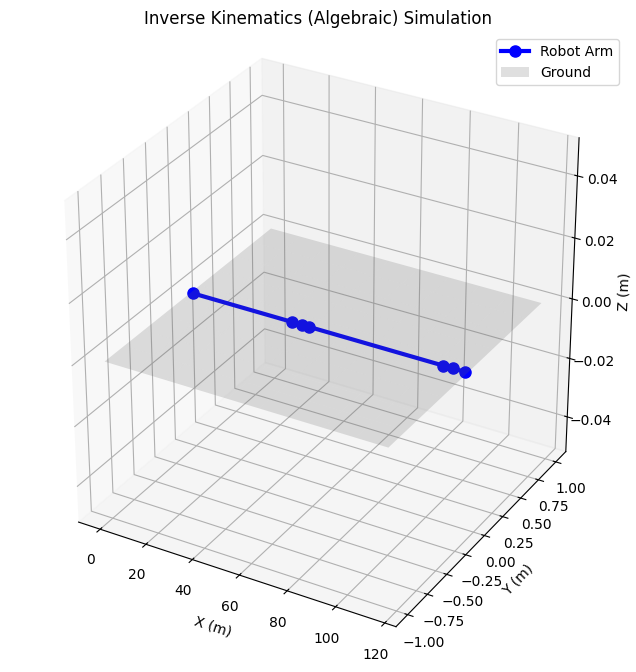

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# --- RobotArm Class ---
class RobotArm:
    def __init__(self, dof, link_lengths=None, dh_params=None, joint_limits=None):
        self.dof = dof
        self.link_lengths = link_lengths if link_lengths is not None else [0] * dof
        self.dh_params = dh_params if dh_params is not None else [[0, 0, 0, 0]] * dof
        self.joint_limits = joint_limits if joint_limits is not None else [(-np.pi, np.pi)] * dof

    def clamp_angles(self, angles):
        return [np.clip(a, self.joint_limits[i][0], self.joint_limits[i][1]) for i, a in enumerate(angles)]

    def dh_transform(self, alpha, a, d, theta):
        T = np.array([
            [np.cos(theta), -np.sin(theta)*np.cos(alpha),  np.sin(theta)*np.sin(alpha), a*np.cos(theta)],
            [np.sin(theta),  np.cos(theta)*np.cos(alpha), -np.cos(theta)*np.sin(alpha), a*np.sin(theta)],
            [0,             np.sin(alpha),                np.cos(alpha),               d],
            [0,             0,                           0,                          1]
        ])
        return T

    def forward_kinematics_dh(self, joint_angles):
        print("\n=== Forward Kinematics Calculation ===")
        T = np.eye(4)
        pos_list = [T[:3, 3].copy()]
        print("Initial Base Frame:\n", np.round(T, decimals=3))

        for i, (alpha, a, d, theta_offset) in enumerate(self.dh_params):
            theta = joint_angles[i] + theta_offset
            print(f"\nJoint {i+1}:")
            print(f"  Parameters: alpha={alpha:.3f}, a={a:.3f}, d={d:.3f}, theta={theta:.3f}")
            T_i = self.dh_transform(alpha, a, d, theta)
            print(f"  Transformation Matrix T{i+1}:\n", np.round(T_i, decimals=3))
            T = np.dot(T, T_i)
            print(f"  Cumulative Transformation after Joint {i+1}:\n", np.round(T, decimals=3))
            pos_list.append(T[:3, 3].copy())

        print("\nFinal End-Effector Pose:\n", np.round(T, decimals=3))
        return T, np.array(pos_list)

    def forward_kinematics_direct(self, joint_angles):
        print("\n=== Forward Kinematics using Direct Method ===")
        T = np.eye(4)
        pos_list = [T[:3, 3].copy()]
        print("Initial Base Frame:\n", np.round(T, decimals=3))

        for i in range(self.dof):
            theta = joint_angles[i]
            a = self.link_lengths[i]
            print(f"\nJoint {i+1}:")
            print(f"  Parameters: theta={theta:.3f}, link_length={a:.3f}")
            R_z = np.array([
                [np.cos(theta), -np.sin(theta), 0, 0],
                [np.sin(theta), np.cos(theta), 0, 0],
                [0, 0, 1, 0],
                [0, 0, 0, 1]
            ])
            T_x = np.array([
                [1, 0, 0, a],
                [0, 1, 0, 0],
                [0, 0, 1, 0],
                [0, 0, 0, 1]
            ])
            T_i = np.dot(R_z, T_x)
            print(f"  Transformation Matrix T{i+1}:\n", np.round(T_i, decimals=3))
            T = np.dot(T, T_i)
            print(f"  Cumulative Transformation after Joint {i+1}:\n", np.round(T, decimals=3))
            pos_list.append(T[:3, 3].copy())

        print("\nFinal End-Effector Pose:\n", np.round(T, decimals=3))
        return T, np.array(pos_list)

    def forward_kinematics_planar(self, joint_angles):
        print("\n=== Planar (2D) Forward Kinematics Calculation ===")
        x, y = 0, 0
        pos_x = [x]
        pos_y = [y]
        pos_list = [[x, y, 0]]
        cum_angle = 0
        print("Initial Position: x=0.000, y=0.000")

        for i, (length, angle) in enumerate(zip(self.link_lengths, joint_angles)):
            cum_angle += angle
            dx = length * np.cos(cum_angle)
            dy = length * np.sin(cum_angle)
            x += dx
            y += dy
            print(f"\nJoint {i+1}:")
            print(f"  Link Length: {length:.3f}, Joint Angle: {angle:.3f}")
            print(f"  Cumulative Angle: {cum_angle:.3f}")
            print(f"  Position after Joint {i+1}: x={x:.3f}, y={y:.3f}")
            pos_x.append(x)
            pos_y.append(y)
            pos_list.append([x, y, 0])

        print("\nFinal End-Effector Position: x={:.3f}, y={:.3f}".format(x, y))
        return np.array([[x, y, 0, 1] for x, y in zip(pos_x, pos_y)]), np.array(pos_list)

    def analytical_jacobian(self, joint_angles):
        n = self.dof
        J = np.zeros((3, n))
        T = np.eye(4)
        pos_list = [np.zeros(3)]
        for i in range(n):
            alpha, a, d, theta_offset = self.dh_params[i]
            theta = joint_angles[i] + theta_offset
            T_i = self.dh_transform(alpha, a, d, theta)
            T = np.dot(T, T_i)
            pos_list.append(T[:3, 3].copy())
        p_e = pos_list[-1]
        for i in range(n):
            p_i = pos_list[i]
            if i == 0:
                z_i = np.dot(T[:3, :3], [0, 0, 1])
            else:
                T_temp = np.eye(4)
                for j in range(i + 1):
                    alpha, a, d, theta_offset = self.dh_params[j]
                    theta = joint_angles[j] + theta_offset
                    T_temp = np.dot(T_temp, self.dh_transform(alpha, a, d, theta))
                z_i = np.dot(T_temp[:3, :3], [0, 0, 1])
            J[:, i] = np.cross(z_i, p_e - p_i)
        return J

    def inverse_kinematics_newton_raphson(self, target, initial_guess, max_iters=100, tol=1e-6, use_analytical_jacobian=True):
        print("\n=== Inverse Kinematics with Newton-Raphson ===")
        joint_angles = np.array(self.clamp_angles(initial_guess), dtype=float)
        n = len(joint_angles)

        for iteration in range(max_iters):
            print(f"\nIteration {iteration + 1}:")
            T, _ = self.forward_kinematics_dh(joint_angles)
            current_pos = T[:3, 3]
            error = target - current_pos
            print(f"  Current Position: [{current_pos[0]:.3f}, {current_pos[1]:.3f}, {current_pos[2]:.3f}]")
            print(f"  Target Position: [{target[0]:.3f}, {target[1]:.3f}, {target[2]:.3f}]")
            print(f"  Position Error: [{error[0]:.3f}, {error[1]:.3f}, {error[2]:.3f}]")
            print(f"  Error Norm: {np.linalg.norm(error):.3f}")
            if np.linalg.norm(error) < tol:
                print(f"IK converged in {iteration + 1} iterations.")
                return joint_angles
            if use_analytical_jacobian:
                J = self.analytical_jacobian(joint_angles)
                print("  Using Analytical Jacobian")
            else:
                J = np.zeros((3, n))
                delta = 1e-6
                for j in range(n):
                    temp_angles = joint_angles.copy()
                    temp_angles[j] += delta
                    T_temp, _ = self.forward_kinematics_dh(temp_angles)
                    pos_temp = T_temp[:3, 3]
                    J[:, j] = (pos_temp - current_pos) / delta
                print("  Using Numerical Jacobian")
            print(f"  Jacobian Matrix:\n", np.round(J, decimals=3))
            try:
                delta_theta = np.linalg.pinv(J).dot(error)
                print(f"  Delta Theta: {[f'{d:.3f}' for d in delta_theta]}")
                joint_angles += delta_theta
                joint_angles = self.clamp_angles(joint_angles)
                print(f"  Updated Joint Angles: {[f'{a:.3f}' for a in joint_angles]}")
            except np.linalg.LinAlgError:
                print("  Singular Jacobian! Aborting.")
                break
        print("IK did not converge within maximum iterations.")
        return joint_angles

    def inverse_kinematics_geometric(self, target, elbow_up=True):
        print("\n=== Inverse Kinematics using Geometric Method ===")
        if self.dof > 3:
            print("Warning: Geometric IK is only implemented for 2R or 3R planar robots. Falling back to Newton-Raphson.")
            return self.inverse_kinematics_newton_raphson(target, [0] * self.dof)

        x, y = target[0], target[1]
        print(f"Target position: x={x:.3f}, y={y:.3f}")

        if len(self.link_lengths) == 2:
            a1, a2 = self.link_lengths
            print(f"Link lengths: a1={a1:.3f}, a2={a2:.3f}")
            r = np.sqrt(x**2 + y**2)
            print(f"Distance to target: r={r:.3f}")
            if r > a1 + a2:
                print("Target is out of reach!")
                theta1 = np.arctan2(y, x)
                theta2 = 0
                return self.clamp_angles([theta1, theta2])
            if r < abs(a1 - a2):
                print("Target is too close (unreachable)!")
                theta1 = np.arctan2(y, x)
                theta2 = np.pi
                return self.clamp_angles([theta1, theta2])
            cos_theta2 = (r**2 - a1**2 - a2**2) / (2 * a1 * a2)
            cos_theta2 = np.clip(cos_theta2, -1.0, 1.0)
            if elbow_up:
                theta2 = np.arccos(cos_theta2)
                print("Using elbow-up configuration")
            else:
                theta2 = -np.arccos(cos_theta2)
                print("Using elbow-down configuration")
            beta = np.arctan2(y, x)
            gamma = np.arctan2(a2 * np.sin(theta2), a1 + a2 * np.cos(theta2))
            theta1 = beta - gamma
            print(f"Calculated joint angles: theta1={theta1:.3f}, theta2={theta2:.3f}")
            return self.clamp_angles([theta1, theta2])
        elif len(self.link_lengths) == 3:
            a1, a2, a3 = self.link_lengths
            print(f"Link lengths: a1={a1:.3f}, a2={a2:.3f}, a3={a3:.3f}")
            phi = 0
            x_wrist = x - a3 * np.cos(phi)
            y_wrist = y - a3 * np.sin(phi)
            print(f"Wrist position: x={x_wrist:.3f}, y={y_wrist:.3f}")
            wrist_target = np.array([x_wrist, y_wrist, 0])
            theta1, theta2 = self.inverse_kinematics_geometric(wrist_target, elbow_up)
            theta3 = phi - theta1 - theta2
            print(f"Calculated joint angles: theta1={theta1:.3f}, theta2={theta2:.3f}, theta3={theta3:.3f}")
            return self.clamp_angles([theta1, theta2, theta3])
        else:
            print("Geometric IK is currently only implemented for 2R or 3R planar robots")
            return None

    def inverse_kinematics_algebraic(self, target):
        print("\n=== Inverse Kinematics using Algebraic Method ===")
        if self.dof > 3:
            print("Warning: Algebraic IK is only implemented for 2R or 3R robots. Falling back to Newton-Raphson.")
            return self.inverse_kinematics_newton_raphson(target, [0] * self.dof)

        x, y, z = target
        print(f"Target position: x={x:.3f}, y={y:.3f}, z={z:.3f}")

        if len(self.link_lengths) == 2 and z == 0:
            a1, a2 = self.link_lengths
            print(f"Link lengths: a1={a1:.3f}, a2={a2:.3f}")
            cos_theta2 = (x**2 + y**2 - a1**2 - a2**2) / (2 * a1 * a2)
            cos_theta2 = np.clip(cos_theta2, -1.0, 1.0)
            theta2 = np.arccos(cos_theta2)
            k1 = a1 + a2 * np.cos(theta2)
            k2 = a2 * np.sin(theta2)
            theta1 = np.arctan2(y, x) - np.arctan2(k2, k1)
            print(f"Calculated joint angles: theta1={theta1:.3f}, theta2={theta2:.3f}")
            return self.clamp_angles([theta1, theta2])
        elif len(self.link_lengths) == 3:
            a1, a2, a3 = self.link_lengths
            print(f"Link lengths: a1={a1:.3f}, a2={a2:.3f}, a3={a3:.3f}")
            if z == 0:
                r = np.sqrt(x**2 + y**2)
                theta1, theta2 = self.inverse_kinematics_algebraic(np.array([x - a3 * x/r, y - a3 * y/r, 0]), [a1, a2])
                theta3 = np.arctan2(y, x) - theta1 - theta2
                print(f"Calculated joint angles: theta1={theta1:.3f}, theta2={theta2:.3f}, theta3={theta3:.3f}")
                return self.clamp_angles([theta1, theta2, theta3])
            else:
                theta1 = np.arctan2(y, x)
                r = np.sqrt(x**2 + y**2)
                theta2, theta3 = self.inverse_kinematics_algebraic(np.array([r, z, 0]), [a2, a3])
                theta2 = theta2 - np.pi/2
                print(f"Calculated joint angles: theta1={theta1:.3f}, theta2={theta2:.3f}, theta3={theta3:.3f}")
                return self.clamp_angles([theta1, theta2, theta3])
        else:
            print("Algebraic IK is currently only implemented for 2R or 3R robots")
            return None

    def simulate_robot(self, pos_list, title="Robot Simulation"):
        print("\n=== Simulating Robot in 3D Space ===")
        fig = plt.figure(figsize=(10, 8))
        ax = fig.add_subplot(111, projection='3d')
        xs, ys, zs = pos_list[:, 0], pos_list[:, 1], pos_list[:, 2]
        ax.plot(xs, ys, zs, '-o', linewidth=3, markersize=8, color='blue', label='Robot Arm')
        x_grid, y_grid = np.meshgrid(np.linspace(min(xs)-1, max(xs)+1, 10),
                                     np.linspace(min(ys)-1, max(ys)+1, 10))
        z_grid = np.zeros_like(x_grid)
        ax.plot_surface(x_grid, y_grid, z_grid, alpha=0.2, color='gray', label='Ground')
        ax.set_xlabel("X (m)")
        ax.set_ylabel("Y (m)")
        ax.set_zlabel("Z (m)")
        ax.set_title(title)
        ax.grid(True)
        ax.legend()
        ax.set_box_aspect([1,1,1])
        plt.show()

# --- Input Collection Functions ---
def get_dh_params(dof):
    dh_params = []
    print(f"\nEnter DH parameters for {dof} joints (alpha, a, d, theta_offset in radians/meters):")
    for i in range(dof):
        while True:
            try:
                params = input(f"Joint {i+1} [alpha a d theta_offset]: ").strip().split()
                alpha, a, d, theta_offset = map(float, params)
                dh_params.append([alpha, a, d, theta_offset])
                break
            except ValueError:
                print("Invalid input. Please enter four numbers separated by spaces.")
    return dh_params

def get_joint_angles(dof):
    while True:
        try:
            angles = input(f"Enter {dof} joint angles in radians (separated by spaces): ").strip().split()
            return [float(angle) for angle in angles]
        except ValueError:
            print("Invalid input. Please enter numbers separated by spaces.")

def get_link_lengths(dof):
    link_lengths = []
    print(f"\nEnter {dof} link lengths in meters:")
    while True:
        try:
            lengths = input(f"Link lengths (separated by spaces): ").strip().split()
            if len(lengths) != dof:
                print(f"Please enter exactly {dof} link lengths.")
                continue
            return [float(length) for length in lengths]
        except ValueError:
            print("Invalid input. Please enter numbers separated by spaces.")

def get_target_position():
    while True:
        try:
            target = input("Enter target position [x y z] in meters (separated by spaces): ").strip().split()
            return np.array([float(coord) for coord in target])
        except ValueError:
            print("Invalid input. Please enter three numbers separated by spaces.")

def get_initial_guess(dof):
    while True:
        try:
            guess = input(f"Enter initial guess for {dof} joint angles in radians (separated by spaces): ").strip().split()
            return [float(angle) for angle in guess]
        except ValueError:
            print("Invalid input. Please enter numbers separated by spaces.")

def get_elbow_config():
    while True:
        choice = input("Choose elbow configuration [u]p or [d]own: ").strip().lower()
        if choice == 'u':
            return True
        elif choice == 'd':
            return False
        else:
            print("Invalid choice. Please enter 'u' or 'd'.")

# --- Test Cases ---
def run_tests():
    print("=== Running Test Cases ===")
    print("\nTest 1: 2R Planar Forward Kinematics")
    robot = RobotArm(2, link_lengths=[1, 1])
    joint_angles = [np.pi/4, np.pi/4]  # 45 degrees each
    T, pos_list = robot.forward_kinematics_planar(joint_angles)
    robot.simulate_robot(pos_list, "Test 1: 2R Planar FK")

    print("\nTest 2: 6-DOF DH Forward and Inverse Kinematics")
    dh_params = [
        [0, 0, 0.1, 0],        # Joint 1
        [-np.pi/2, 0, 0, 0],   # Joint 2
        [0, 1, 0, 0],          # Joint 3
        [-np.pi/2, 0.5, 0, 0], # Joint 4
        [np.pi/2, 0, 0, 0],    # Joint 5
        [-np.pi/2, 0.2, 0, 0]  # Joint 6
    ]
    robot = RobotArm(6, dh_params=dh_params)
    joint_angles = [0, np.pi/4, np.pi/4, 0, np.pi/4, 0]
    T, pos_list = robot.forward_kinematics_dh(joint_angles)
    robot.simulate_robot(pos_list, "Test 2: 6-DOF Forward Kinematics")
    target = np.array([1.0, 0.5, 0.8])
    initial_guess = [0.1, 0.1, 0.1, 0.1, 0.1, 0.1]  # Slightly non-zero to help convergence
    ik_angles = robot.inverse_kinematics_newton_raphson(target, initial_guess)
    T_ik, pos_list_ik = robot.forward_kinematics_dh(ik_angles)
    print(f"\nResulting End-Effector Position: [{T_ik[0,3]:.3f}, {T_ik[1,3]:.3f}, {T_ik[2,3]:.3f}]")
    robot.simulate_robot(pos_list_ik, "Test 2: 6-DOF Inverse Kinematics")

# --- Main Execution ---
if __name__ == "__main__":
    print("=== Robot Kinematics Simulator ===")
    print("Select Main Mode:")
    print("  [F]orward Kinematics")
    print("  [I]nverse Kinematics")
    print("  [T]est")
    mode = input("Enter F, I, or T: ").strip().lower()

    while mode not in ['f', 'i', 't']:
        print("Invalid choice. Please enter 'F', 'I' or 'T'.")
        mode = input("Enter F, I, or T: ").strip().lower()

    if mode == 't':
        run_tests()
    else:
        while True:
            try:
                dof = int(input("Enter number of DOF (e.g., 2, 3, 6): "))
                if dof > 0:
                    break
                print("DOF must be positive.")
            except ValueError:
                print("Invalid input. Please enter an integer.")

        robot = RobotArm(dof)

        if mode == 'f':
            print("\n=== Forward Kinematics Mode ===")
            print("Select FK Method:")
            print("  [1] DH Parameters")
            print("  [2] Direct Method")
            print("  [3] Planar Method (2D)")
            fk_method = input("Enter method (1-3): ").strip()

            while fk_method not in ['1', '2', '3']:
                print("Invalid choice. Please enter a number between 1 and 3.")
                fk_method = input("Enter method (1-3): ").strip()

            if fk_method == '1':
                dh_params = get_dh_params(dof)
                joint_angles = get_joint_angles(dof)
                robot.dh_params = dh_params
                T, pos_list = robot.forward_kinematics_dh(joint_angles)
                robot.simulate_robot(pos_list, "Forward Kinematics (DH) Simulation")

            elif fk_method == '2':
                link_lengths = get_link_lengths(dof)
                joint_angles = get_joint_angles(dof)
                robot.link_lengths = link_lengths
                T, pos_list = robot.forward_kinematics_direct(joint_angles)
                robot.simulate_robot(pos_list, "Forward Kinematics (Direct) Simulation")

            elif fk_method == '3':
                if dof > 3:
                    print("Warning: Planar method works best with 2 or 3 DOF.")
                link_lengths = get_link_lengths(dof)
                joint_angles = get_joint_angles(dof)
                robot.link_lengths = link_lengths
                T, pos_list = robot.forward_kinematics_planar(joint_angles)
                robot.simulate_robot(pos_list, "Forward Kinematics (Planar) Simulation")

        elif mode == 'i':
            print("\n=== Inverse Kinematics Mode ===")
            print("Select IK Method:")
            print("  [1] Newton-Raphson with DH Parameters")
            print("  [2] Geometric Method (for 2R or 3R planar robots)")
            print("  [3] Algebraic Method (for 2R or 3R robots)")
            ik_method = input("Enter method (1-3): ").strip()

            while ik_method not in ['1', '2', '3']:
                print("Invalid choice. Please enter a number between 1 and 3.")
                ik_method = input("Enter method (1-3): ").strip()

            target = get_target_position()

            if ik_method == '1':
                dh_params = get_dh_params(dof)
                initial_guess = get_initial_guess(dof)
                robot.dh_params = dh_params
                ik_angles = robot.inverse_kinematics_newton_raphson(target, initial_guess)
                print(f"\nFinal Joint Angles from IK: {[f'{angle:.3f}' for angle in ik_angles]}")
                T_ik, pos_list_ik = robot.forward_kinematics_dh(ik_angles)
                print(f"Resulting End-Effector Position: [{T_ik[0,3]:.3f}, {T_ik[1,3]:.3f}, {T_ik[2,3]:.3f}]")
                robot.simulate_robot(pos_list_ik, "Inverse Kinematics (Newton-Raphson) Simulation")

            elif ik_method == '2':
                if dof > 3:
                    print("Warning: Geometric method is designed for 2 or 3 DOF planar robots.")
                link_lengths = get_link_lengths(dof)
                elbow_up = get_elbow_config()
                robot.link_lengths = link_lengths
                ik_angles = robot.inverse_kinematics_geometric(target, elbow_up)
                if ik_angles is not None:
                    print(f"\nFinal Joint Angles from IK: {[f'{angle:.3f}' for angle in ik_angles]}")
                    T_ik, pos_list_ik = robot.forward_kinematics_planar(ik_angles)
                    print(f"Resulting End-Effector Position: [{pos_list_ik[-1][0]:.3f}, {pos_list_ik[-1][1]:.3f}, {pos_list_ik[-1][2]:.3f}]")
                    robot.simulate_robot(pos_list_ik, "Inverse Kinematics (Geometric) Simulation")

            elif ik_method == '3':
                if dof > 3:
                    print("Warning: Algebraic method is currently implemented for 2 or 3 DOF robots only.")
                link_lengths = get_link_lengths(dof)
                robot.link_lengths = link_lengths
                ik_angles = robot.inverse_kinematics_algebraic(target)
                if ik_angles is not None:
                    print(f"\nFinal Joint Angles from IK: {[f'{angle:.3f}' for angle in ik_angles]}")
                    if target[2] == 0:
                        T_ik, pos_list_ik = robot.forward_kinematics_planar(ik_angles)
                    else:
                        T_ik, pos_list_ik = robot.forward_kinematics_direct(ik_angles)
                    print(f"Resulting End-Effector Position: [{pos_list_ik[-1][0]:.3f}, {pos_list_ik[-1][1]:.3f}, {pos_list_ik[-1][2]:.3f}]")
                    robot.simulate_robot(pos_list_ik, "Inverse Kinematics (Algebraic) Simulation")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from mpl_toolkits.mplot3d import Axes3D
from IPython.display import Video, display

# Assuming RobotArm class is defined in the previous cell
# Install ffmpeg if not already installed (run in a separate cell first)
# !apt-get install -y ffmpeg

def animate_robot_arm(robot, start_angles, end_angles, target=None, frames=50, interval=50, title="Robot Arm Animation"):
    """
    Animate the robot arm moving from start_angles to end_angles.

    Args:
        robot (RobotArm): Instance of RobotArm class from previous cell.
        start_angles (list): Initial joint angles (radians).
        end_angles (list): Final joint angles (radians).
        target (np.array): Target position to mark (optional).
        frames (int): Number of animation frames.
        interval (int): Delay between frames in milliseconds.
        title (str): Animation title.
    """
    print("\n=== Starting Robot Arm Animation ===")
    print(f"Start Angles: {[f'{a:.3f}' for a in start_angles]}")
    print(f"End Angles: {[f'{a:.3f}' for a in end_angles]}")

    # Validate input lengths
    if len(start_angles) != len(end_angles) or len(start_angles) != robot.dof:
        print(f"Error: Mismatched DOF. Start={len(start_angles)}, End={len(end_angles)}, Robot DOF={robot.dof}")
        return

    # Interpolate joint angles linearly between start and end
    interpolated_angles = []
    for i in range(len(start_angles)):
        interp = np.linspace(start_angles[i], end_angles[i], frames)
        interpolated_angles.append(interp)
    interpolated_angles = np.array(interpolated_angles).T  # Shape: (frames, dof)
    print(f"Interpolated Angles Shape: {interpolated_angles.shape}")
    print(f"Sample Angles (Frame 1, Frame {frames}): {interpolated_angles[0]}, {interpolated_angles[-1]}")

    # Compute positions to determine plot limits
    pos_list_start, _ = robot.forward_kinematics_dh(start_angles)
    pos_list_end, _ = robot.forward_kinematics_dh(end_angles)
    all_positions = np.vstack((pos_list_start, pos_list_end))
    x_min, x_max = all_positions[:, 0].min(), all_positions[:, 0].max()
    y_min, y_max = all_positions[:, 1].min(), all_positions[:, 1].max()
    z_min, z_max = all_positions[:, 2].min(), all_positions[:, 2].max()
    padding = 0.5  # Add padding to the limits
    x_range = max(x_max - x_min, 1.0) + padding
    y_range = max(y_max - y_min, 1.0) + padding
    z_range = max(z_max - z_min, 1.0) + padding

    # Set up the 3D plot
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')
    ax.set_xlabel("X (m)")
    ax.set_ylabel("Y (m)")
    ax.set_zlabel("Z (m)")
    ax.set_title(title)
    ax.grid(True)
    ax.set_box_aspect([1, 1, 1])

    # Ground plane
    x_grid, y_grid = np.meshgrid(np.linspace(x_min - padding, x_max + padding, 10),
                                 np.linspace(y_min - padding, y_max + padding, 10))
    z_grid = np.zeros_like(x_grid)
    ax.plot_surface(x_grid, y_grid, z_grid, alpha=0.2, color='gray', label='Ground')

    # Initialize the arm plot with start position
    print(f"Initial Position List: {pos_list_start}")
    line, = ax.plot(pos_list_start[:, 0], pos_list_start[:, 1], pos_list_start[:, 2],
                    '-o', linewidth=3, markersize=8, color='blue', label='Robot Arm')

    # Plot the target position if provided
    if target is not None:
        ax.scatter([target[0]], [target[1]], [target[2]], color='red', s=100, label='Target')

    ax.legend()

    # Set plot limits based on the actual workspace
    ax.set_xlim(x_min - padding, x_max + padding)
    ax.set_ylim(y_min - padding, y_max + padding)
    ax.set_zlim(max(z_min - padding, 0), z_max + padding)
    print(f"Plot limits: X={x_min - padding:.3f} to {x_max + padding:.3f}, "
          f"Y={y_min - padding:.3f} to {y_max + padding:.3f}, "
          f"Z={max(z_min - padding, 0):.3f} to {z_max + padding:.3f}")

    def update(frame):
        """Update function for animation frames."""
        current_angles = interpolated_angles[frame]
        print(f"Frame {frame+1}/{frames}: Joint Angles = {[f'{a:.3f}' for a in current_angles]}")
        pos_list, _ = robot.forward_kinematics_dh(current_angles)
        print(f"Frame Position List: {pos_list}")
        line.set_data(pos_list[:, 0], pos_list[:, 1])  # Update x, y
        line.set_3d_properties(pos_list[:, 2])        # Update z
        return line,

    # Create the animation and retain it
    anim = FuncAnimation(fig, update, frames=frames, interval=interval, blit=False, repeat=False)
    plt.close()  # Avoid inline display issues in Colab
    print("=== Saving Animation to MP4 ===")

    # Save the animation to an MP4 file
    anim.save('robot_arm_animation.mp4', writer='ffmpeg', dpi=300)
    print("Animation saved as 'robot_arm_animation.mp4' in /content/")

    # Display the video in Colab
    video = Video('robot_arm_animation.mp4')
    display(video)
    print("=== Animation Complete ===")
    return anim  # Optional, for further manipulation

# Example usage with your RobotArm class
if __name__ == "__main__":
    # Create a 6-DOF robot (same as Test 2)
    dh_params = [
        [0, 0, 0.1, 0],        # Joint 1
        [-np.pi/2, 0, 0, 0],   # Joint 2
        [0, 1, 0, 0],          # Joint 3
        [-np.pi/2, 0.5, 0, 0], # Joint 4
        [np.pi/2, 0, 0, 0],    # Joint 5
        [-np.pi/2, 0.2, 0, 0]  # Joint 6
    ]
    robot = RobotArm(6, dh_params=dh_params)

    # Use angles from Test 2
    start_angles = [0, np.pi/4, np.pi/4, 0, np.pi/4, 0]  # Initial pose from Test 2
    target = np.array([1.0, 0.5, 0.8])  # Target from Test 2
    initial_guess = [0.1, 0.1, 0.1, 0.1, 0.1, 0.1]  # Same as Test 2
    end_angles = robot.inverse_kinematics_newton_raphson(target, initial_guess, use_analytical_jacobian=True)
    print(f"Computed End Angles: {[f'{a:.3f}' for a in end_angles]}")

    # Run the animation and display the result
    anim = animate_robot_arm(robot, start_angles, end_angles, target=target, frames=50, interval=50,
                             title="6-DOF Robot Arm Reaching Target (Test 2)")

Streaming output truncated to the last 5000 lines.

Final End-Effector Pose:
 [[ 0.854  0.146 -0.5    0.921]
 [-0.146 -0.854 -0.5    0.721]
 [-0.5    0.5   -0.707 -1.061]
 [ 0.     0.     0.     1.   ]]

=== Forward Kinematics Calculation ===
Initial Base Frame:
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]

Joint 1:
  Parameters: alpha=0.000, a=0.000, d=0.100, theta=3.142
  Transformation Matrix T1:
 [[-1.  -0.   0.  -0. ]
 [ 0.  -1.   0.   0. ]
 [ 0.   0.   1.   0.1]
 [ 0.   0.   0.   1. ]]
  Cumulative Transformation after Joint 1:
 [[-1.  -0.   0.   0. ]
 [ 0.  -1.   0.   0. ]
 [ 0.   0.   1.   0.1]
 [ 0.   0.   0.   1. ]]

Joint 2:
  Parameters: alpha=-1.571, a=0.000, d=0.000, theta=3.142
  Transformation Matrix T2:
 [[-1. -0. -0. -0.]
 [ 0. -0. -1.  0.]
 [ 0. -1.  0.  0.]
 [ 0.  0.  0.  1.]]
  Cumulative Transformation after Joint 2:
 [[ 1.   0.   0.   0. ]
 [-0.   0.   1.   0. ]
 [ 0.  -1.   0.   0.1]
 [ 0.   0.   0.   1. ]]

Joint 3:
  Parameters: alpha=0.000, a

=== Animation Complete ===


=== Robot Kinematics Simulator ===
Select Main Mode:
  [F]orward Kinematics
  [I]nverse Kinematics
  [T]est
Enter F, I, or T: F
Enter number of DOF (e.g., 2, 3, 6): 3

=== Forward Kinematics Mode ===
Select FK Method:
  [1] DH Parameters
  [2] Direct Method
  [3] Planar Method (2D)
Enter method (1-3): 3

Enter 3 link lengths in meters:
Link lengths (separated by spaces): 23 3 45
Enter 3 joint angles in radians (separated by spaces): 33 5 67

=== Planar (2D) Forward Kinematics Calculation ===
Initial Position: x=0.000, y=0.000

Joint 1:
  Link Length: 23.000, Joint Angle: 33.000
  Cumulative Angle: 33.000
  Position after Joint 1: x=-0.305, y=22.998

Joint 2:
  Link Length: 3.000, Joint Angle: 5.000
  Cumulative Angle: 38.000
  Position after Joint 2: x=2.560, y=23.887

Joint 3:
  Link Length: 45.000, Joint Angle: 67.000
  Cumulative Angle: 105.000
  Position after Joint 3: x=-8.283, y=-19.787

Final End-Effector Position: x=-8.283, y=-19.787

=== Simulating Robot in 3D Space ===


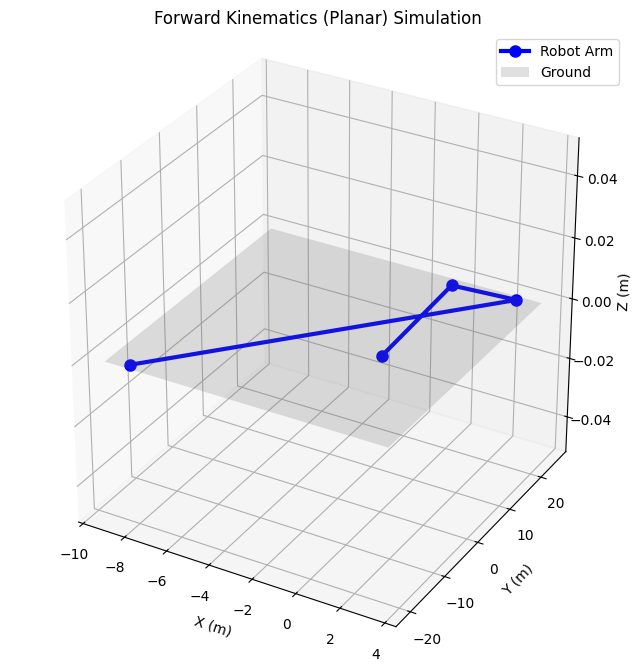


Results stored for animation:
Start Angles: [0, 0, 0]
End Angles: [33.0, 5.0, 67.0]


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Global variables to store results for the animation cell
global robot, start_angles, end_angles
robot = None
start_angles = None
end_angles = None

# --- RobotArm Class ---
class RobotArm:
    def __init__(self, dof, link_lengths=None, dh_params=None, joint_limits=None):
        self.dof = dof
        self.link_lengths = link_lengths if link_lengths is not None else [0] * dof
        self.dh_params = dh_params if dh_params is not None else [[0, 0, 0, 0]] * dof
        self.joint_limits = joint_limits if joint_limits is not None else [(-np.pi, np.pi)] * dof

    def clamp_angles(self, angles):
        return [np.clip(a, self.joint_limits[i][0], self.joint_limits[i][1]) for i, a in enumerate(angles)]

    def dh_transform(self, alpha, a, d, theta):
        T = np.array([
            [np.cos(theta), -np.sin(theta)*np.cos(alpha),  np.sin(theta)*np.sin(alpha), a*np.cos(theta)],
            [np.sin(theta),  np.cos(theta)*np.cos(alpha), -np.cos(theta)*np.sin(alpha), a*np.sin(theta)],
            [0,             np.sin(alpha),                np.cos(alpha),               d],
            [0,             0,                           0,                          1]
        ])
        return T

    def forward_kinematics_dh(self, joint_angles):
        print("\n=== Forward Kinematics Calculation ===")
        T = np.eye(4)
        pos_list = [T[:3, 3].copy()]
        print("Initial Base Frame:\n", np.round(T, decimals=3))

        for i, (alpha, a, d, theta_offset) in enumerate(self.dh_params):
            theta = joint_angles[i] + theta_offset
            print(f"\nJoint {i+1}:")
            print(f"  Parameters: alpha={alpha:.3f}, a={a:.3f}, d={d:.3f}, theta={theta:.3f}")
            T_i = self.dh_transform(alpha, a, d, theta)
            print(f"  Transformation Matrix T{i+1}:\n", np.round(T_i, decimals=3))
            T = np.dot(T, T_i)
            print(f"  Cumulative Transformation after Joint {i+1}:\n", np.round(T, decimals=3))
            pos_list.append(T[:3, 3].copy())

        print("\nFinal End-Effector Pose:\n", np.round(T, decimals=3))
        return T, np.array(pos_list)

    def forward_kinematics_direct(self, joint_angles):
        print("\n=== Forward Kinematics using Direct Method ===")
        T = np.eye(4)
        pos_list = [T[:3, 3].copy()]
        print("Initial Base Frame:\n", np.round(T, decimals=3))

        for i in range(self.dof):
            theta = joint_angles[i]
            a = self.link_lengths[i]
            print(f"\nJoint {i+1}:")
            print(f"  Parameters: theta={theta:.3f}, link_length={a:.3f}")
            R_z = np.array([
                [np.cos(theta), -np.sin(theta), 0, 0],
                [np.sin(theta), np.cos(theta), 0, 0],
                [0, 0, 1, 0],
                [0, 0, 0, 1]
            ])
            T_x = np.array([
                [1, 0, 0, a],
                [0, 1, 0, 0],
                [0, 0, 1, 0],
                [0, 0, 0, 1]
            ])
            T_i = np.dot(R_z, T_x)
            print(f"  Transformation Matrix T{i+1}:\n", np.round(T_i, decimals=3))
            T = np.dot(T, T_i)
            print(f"  Cumulative Transformation after Joint {i+1}:\n", np.round(T, decimals=3))
            pos_list.append(T[:3, 3].copy())

        print("\nFinal End-Effector Pose:\n", np.round(T, decimals=3))
        return T, np.array(pos_list)

    def forward_kinematics_planar(self, joint_angles):
        print("\n=== Planar (2D) Forward Kinematics Calculation ===")
        x, y = 0, 0
        pos_x = [x]
        pos_y = [y]
        pos_list = [[x, y, 0]]
        cum_angle = 0
        print("Initial Position: x=0.000, y=0.000")

        for i, (length, angle) in enumerate(zip(self.link_lengths, joint_angles)):
            cum_angle += angle
            dx = length * np.cos(cum_angle)
            dy = length * np.sin(cum_angle)
            x += dx
            y += dy
            print(f"\nJoint {i+1}:")
            print(f"  Link Length: {length:.3f}, Joint Angle: {angle:.3f}")
            print(f"  Cumulative Angle: {cum_angle:.3f}")
            print(f"  Position after Joint {i+1}: x={x:.3f}, y={y:.3f}")
            pos_x.append(x)
            pos_y.append(y)
            pos_list.append([x, y, 0])

        print("\nFinal End-Effector Position: x={:.3f}, y={:.3f}".format(x, y))
        return np.array([[x, y, 0, 1] for x, y in zip(pos_x, pos_y)]), np.array(pos_list)

    def analytical_jacobian(self, joint_angles):
        n = self.dof
        J = np.zeros((3, n))
        T = np.eye(4)
        pos_list = [np.zeros(3)]
        for i in range(n):
            alpha, a, d, theta_offset = self.dh_params[i]
            theta = joint_angles[i] + theta_offset
            T_i = self.dh_transform(alpha, a, d, theta)
            T = np.dot(T, T_i)
            pos_list.append(T[:3, 3].copy())
        p_e = pos_list[-1]
        for i in range(n):
            p_i = pos_list[i]
            if i == 0:
                z_i = np.dot(T[:3, :3], [0, 0, 1])
            else:
                T_temp = np.eye(4)
                for j in range(i + 1):
                    alpha, a, d, theta_offset = self.dh_params[j]
                    theta = joint_angles[j] + theta_offset
                    T_temp = np.dot(T_temp, self.dh_transform(alpha, a, d, theta))
                z_i = np.dot(T_temp[:3, :3], [0, 0, 1])
            J[:, i] = np.cross(z_i, p_e - p_i)
        return J

    def inverse_kinematics_newton_raphson(self, target, initial_guess, max_iters=100, tol=1e-6, use_analytical_jacobian=True):
        print("\n=== Inverse Kinematics with Newton-Raphson ===")
        joint_angles = np.array(self.clamp_angles(initial_guess), dtype=float)
        n = len(joint_angles)

        for iteration in range(max_iters):
            print(f"\nIteration {iteration + 1}:")
            T, _ = self.forward_kinematics_dh(joint_angles)
            current_pos = T[:3, 3]
            error = target - current_pos
            print(f"  Current Position: [{current_pos[0]:.3f}, {current_pos[1]:.3f}, {current_pos[2]:.3f}]")
            print(f"  Target Position: [{target[0]:.3f}, {target[1]:.3f}, {target[2]:.3f}]")
            print(f"  Position Error: [{error[0]:.3f}, {error[1]:.3f}, {error[2]:.3f}]")
            print(f"  Error Norm: {np.linalg.norm(error):.3f}")
            if np.linalg.norm(error) < tol:
                print(f"IK converged in {iteration + 1} iterations.")
                return joint_angles
            if use_analytical_jacobian:
                J = self.analytical_jacobian(joint_angles)
                print("  Using Analytical Jacobian")
            else:
                J = np.zeros((3, n))
                delta = 1e-6
                for j in range(n):
                    temp_angles = joint_angles.copy()
                    temp_angles[j] += delta
                    T_temp, _ = self.forward_kinematics_dh(temp_angles)
                    pos_temp = T_temp[:3, 3]
                    J[:, j] = (pos_temp - current_pos) / delta
                print("  Using Numerical Jacobian")
            print(f"  Jacobian Matrix:\n", np.round(J, decimals=3))
            try:
                delta_theta = np.linalg.pinv(J).dot(error)
                print(f"  Delta Theta: {[f'{d:.3f}' for d in delta_theta]}")
                joint_angles += delta_theta
                joint_angles = self.clamp_angles(joint_angles)
                print(f"  Updated Joint Angles: {[f'{a:.3f}' for a in joint_angles]}")
            except np.linalg.LinAlgError:
                print("  Singular Jacobian! Aborting.")
                break
        print("IK did not converge within maximum iterations.")
        return joint_angles

    def inverse_kinematics_geometric(self, target, elbow_up=True):
        print("\n=== Inverse Kinematics using Geometric Method ===")
        if self.dof > 3:
            print("Warning: Geometric IK is only implemented for 2R or 3R planar robots. Falling back to Newton-Raphson.")
            return self.inverse_kinematics_newton_raphson(target, [0] * self.dof)

        x, y = target[0], target[1]
        print(f"Target position: x={x:.3f}, y={y:.3f}")

        if len(self.link_lengths) == 2:
            a1, a2 = self.link_lengths
            print(f"Link lengths: a1={a1:.3f}, a2={a2:.3f}")
            r = np.sqrt(x**2 + y**2)
            print(f"Distance to target: r={r:.3f}")
            if r > a1 + a2:
                print("Target is out of reach!")
                theta1 = np.arctan2(y, x)
                theta2 = 0
                return self.clamp_angles([theta1, theta2])
            if r < abs(a1 - a2):
                print("Target is too close (unreachable)!")
                theta1 = np.arctan2(y, x)
                theta2 = np.pi
                return self.clamp_angles([theta1, theta2])
            cos_theta2 = (r**2 - a1**2 - a2**2) / (2 * a1 * a2)
            cos_theta2 = np.clip(cos_theta2, -1.0, 1.0)
            if elbow_up:
                theta2 = np.arccos(cos_theta2)
                print("Using elbow-up configuration")
            else:
                theta2 = -np.arccos(cos_theta2)
                print("Using elbow-down configuration")
            beta = np.arctan2(y, x)
            gamma = np.arctan2(a2 * np.sin(theta2), a1 + a2 * np.cos(theta2))
            theta1 = beta - gamma
            print(f"Calculated joint angles: theta1={theta1:.3f}, theta2={theta2:.3f}")
            return self.clamp_angles([theta1, theta2])
        elif len(self.link_lengths) == 3:
            a1, a2, a3 = self.link_lengths
            print(f"Link lengths: a1={a1:.3f}, a2={a2:.3f}, a3={a3:.3f}")
            phi = 0
            x_wrist = x - a3 * np.cos(phi)
            y_wrist = y - a3 * np.sin(phi)
            print(f"Wrist position: x={x_wrist:.3f}, y={y_wrist:.3f}")
            wrist_target = np.array([x_wrist, y_wrist, 0])
            theta1, theta2 = self.inverse_kinematics_geometric(wrist_target, elbow_up)
            theta3 = phi - theta1 - theta2
            print(f"Calculated joint angles: theta1={theta1:.3f}, theta2={theta2:.3f}, theta3={theta3:.3f}")
            return self.clamp_angles([theta1, theta2, theta3])
        else:
            print("Geometric IK is currently only implemented for 2R or 3R planar robots")
            return None

    def inverse_kinematics_algebraic(self, target):
        print("\n=== Inverse Kinematics using Algebraic Method ===")
        if self.dof > 3:
            print("Warning: Algebraic IK is only implemented for 2R or 3R robots. Falling back to Newton-Raphson.")
            return self.inverse_kinematics_newton_raphson(target, [0] * self.dof)

        x, y, z = target
        print(f"Target position: x={x:.3f}, y={y:.3f}, z={z:.3f}")

        if len(self.link_lengths) == 2 and z == 0:
            a1, a2 = self.link_lengths
            print(f"Link lengths: a1={a1:.3f}, a2={a2:.3f}")
            cos_theta2 = (x**2 + y**2 - a1**2 - a2**2) / (2 * a1 * a2)
            cos_theta2 = np.clip(cos_theta2, -1.0, 1.0)
            theta2 = np.arccos(cos_theta2)
            k1 = a1 + a2 * np.cos(theta2)
            k2 = a2 * np.sin(theta2)
            theta1 = np.arctan2(y, x) - np.arctan2(k2, k1)
            print(f"Calculated joint angles: theta1={theta1:.3f}, theta2={theta2:.3f}")
            return self.clamp_angles([theta1, theta2])
        elif len(self.link_lengths) == 3:
            a1, a2, a3 = self.link_lengths
            print(f"Link lengths: a1={a1:.3f}, a2={a2:.3f}, a3={a3:.3f}")
            if z == 0:
                r = np.sqrt(x**2 + y**2)
                theta1, theta2 = self.inverse_kinematics_algebraic(np.array([x - a3 * x/r, y - a3 * y/r, 0]), [a1, a2])
                theta3 = np.arctan2(y, x) - theta1 - theta2
                print(f"Calculated joint angles: theta1={theta1:.3f}, theta2={theta2:.3f}, theta3={theta3:.3f}")
                return self.clamp_angles([theta1, theta2, theta3])
            else:
                theta1 = np.arctan2(y, x)
                r = np.sqrt(x**2 + y**2)
                theta2, theta3 = self.inverse_kinematics_algebraic(np.array([r, z, 0]), [a2, a3])
                theta2 = theta2 - np.pi/2
                print(f"Calculated joint angles: theta1={theta1:.3f}, theta2={theta2:.3f}, theta3={theta3:.3f}")
                return self.clamp_angles([theta1, theta2, theta3])
        else:
            print("Algebraic IK is currently only implemented for 2R or 3R robots")
            return None

    def simulate_robot(self, pos_list, title="Robot Simulation"):
        print("\n=== Simulating Robot in 3D Space ===")
        fig = plt.figure(figsize=(10, 8))
        ax = fig.add_subplot(111, projection='3d')
        xs, ys, zs = pos_list[:, 0], pos_list[:, 1], pos_list[:, 2]
        ax.plot(xs, ys, zs, '-o', linewidth=3, markersize=8, color='blue', label='Robot Arm')
        x_grid, y_grid = np.meshgrid(np.linspace(min(xs)-1, max(xs)+1, 10),
                                     np.linspace(min(ys)-1, max(ys)+1, 10))
        z_grid = np.zeros_like(x_grid)
        ax.plot_surface(x_grid, y_grid, z_grid, alpha=0.2, color='gray', label='Ground')
        ax.set_xlabel("X (m)")
        ax.set_ylabel("Y (m)")
        ax.set_zlabel("Z (m)")
        ax.set_title(title)
        ax.grid(True)
        ax.legend()
        ax.set_box_aspect([1,1,1])
        plt.show()

# --- Input Collection Functions ---
def get_dh_params(dof):
    dh_params = []
    print(f"\nEnter DH parameters for {dof} joints (alpha, a, d, theta_offset in radians/meters):")
    for i in range(dof):
        while True:
            try:
                params = input(f"Joint {i+1} [alpha a d theta_offset]: ").strip().split()
                alpha, a, d, theta_offset = map(float, params)
                dh_params.append([alpha, a, d, theta_offset])
                break
            except ValueError:
                print("Invalid input. Please enter four numbers separated by spaces.")
    return dh_params

def get_joint_angles(dof):
    while True:
        try:
            angles = input(f"Enter {dof} joint angles in radians (separated by spaces): ").strip().split()
            return [float(angle) for angle in angles]
        except ValueError:
            print("Invalid input. Please enter numbers separated by spaces.")

def get_link_lengths(dof):
    link_lengths = []
    print(f"\nEnter {dof} link lengths in meters:")
    while True:
        try:
            lengths = input(f"Link lengths (separated by spaces): ").strip().split()
            if len(lengths) != dof:
                print(f"Please enter exactly {dof} link lengths.")
                continue
            return [float(length) for length in lengths]
        except ValueError:
            print("Invalid input. Please enter numbers separated by spaces.")

def get_target_position():
    while True:
        try:
            target = input("Enter target position [x y z] in meters (separated by spaces): ").strip().split()
            return np.array([float(coord) for coord in target])
        except ValueError:
            print("Invalid input. Please enter three numbers separated by spaces.")

def get_initial_guess(dof):
    while True:
        try:
            guess = input(f"Enter initial guess for {dof} joint angles in radians (separated by spaces): ").strip().split()
            return [float(angle) for angle in guess]
        except ValueError:
            print("Invalid input. Please enter numbers separated by spaces.")

def get_elbow_config():
    while True:
        choice = input("Choose elbow configuration [u]p or [d]own: ").strip().lower()
        if choice == 'u':
            return True
        elif choice == 'd':
            return False
        else:
            print("Invalid choice. Please enter 'u' or 'd'.")

# --- Test Cases ---
def run_tests():
    global robot, start_angles, end_angles
    print("=== Running Test Cases ===")
    print("\nTest 1: 2R Planar Forward Kinematics")
    robot = RobotArm(2, link_lengths=[1, 1])
    joint_angles = [np.pi/4, np.pi/4]  # 45 degrees each
    start_angles = [0, 0]  # Start at rest
    end_angles = joint_angles
    T, pos_list = robot.forward_kinematics_planar(joint_angles)
    robot.simulate_robot(pos_list, "Test 1: 2R Planar FK")

    print("\nTest 2: 6-DOF DH Forward and Inverse Kinematics")
    dh_params = [
        [0, 0, 0.1, 0],        # Joint 1
        [-np.pi/2, 0, 0, 0],   # Joint 2
        [0, 1, 0, 0],          # Joint 3
        [-np.pi/2, 0.5, 0, 0], # Joint 4
        [np.pi/2, 0, 0, 0],    # Joint 5
        [-np.pi/2, 0.2, 0, 0]  # Joint 6
    ]
    robot = RobotArm(6, dh_params=dh_params)
    joint_angles = [0, np.pi/4, np.pi/4, 0, np.pi/4, 0]
    T, pos_list = robot.forward_kinematics_dh(joint_angles)
    robot.simulate_robot(pos_list, "Test 2: 6-DOF Forward Kinematics")
    target = np.array([1.0, 0.5, 0.8])
    initial_guess = [0.1, 0.1, 0.1, 0.1, 0.1, 0.1]
    start_angles = [0, 0, 0, 0, 0, 0]  # Start at rest
    end_angles = robot.inverse_kinematics_newton_raphson(target, initial_guess)
    T_ik, pos_list_ik = robot.forward_kinematics_dh(end_angles)
    print(f"\nResulting End-Effector Position: [{T_ik[0,3]:.3f}, {T_ik[1,3]:.3f}, {T_ik[2,3]:.3f}]")
    robot.simulate_robot(pos_list_ik, "Test 2: 6-DOF Inverse Kinematics")

# --- Main Execution ---
if __name__ == "__main__":
    global robot, start_angles, end_angles
    print("=== Robot Kinematics Simulator ===")
    print("Select Main Mode:")
    print("  [F]orward Kinematics")
    print("  [I]nverse Kinematics")
    print("  [T]est")
    mode = input("Enter F, I, or T: ").strip().lower()

    while mode not in ['f', 'i', 't']:
        print("Invalid choice. Please enter 'F', 'I' or 'T'.")
        mode = input("Enter F, I, or T: ").strip().lower()

    if mode == 't':
        run_tests()
    else:
        while True:
            try:
                dof = int(input("Enter number of DOF (e.g., 2, 3, 6): "))
                if dof > 0:
                    break
                print("DOF must be positive.")
            except ValueError:
                print("Invalid input. Please enter an integer.")

        robot = RobotArm(dof)

        if mode == 'f':
            print("\n=== Forward Kinematics Mode ===")
            print("Select FK Method:")
            print("  [1] DH Parameters")
            print("  [2] Direct Method")
            print("  [3] Planar Method (2D)")
            fk_method = input("Enter method (1-3): ").strip()

            while fk_method not in ['1', '2', '3']:
                print("Invalid choice. Please enter a number between 1 and 3.")
                fk_method = input("Enter method (1-3): ").strip()

            if fk_method == '1':
                dh_params = get_dh_params(dof)
                joint_angles = get_joint_angles(dof)
                robot.dh_params = dh_params
                start_angles = [0] * dof  # Start at rest
                end_angles = joint_angles
                T, pos_list = robot.forward_kinematics_dh(joint_angles)
                robot.simulate_robot(pos_list, "Forward Kinematics (DH) Simulation")

            elif fk_method == '2':
                link_lengths = get_link_lengths(dof)
                joint_angles = get_joint_angles(dof)
                robot.link_lengths = link_lengths
                start_angles = [0] * dof  # Start at rest
                end_angles = joint_angles
                T, pos_list = robot.forward_kinematics_direct(joint_angles)
                robot.simulate_robot(pos_list, "Forward Kinematics (Direct) Simulation")

            elif fk_method == '3':
                if dof > 3:
                    print("Warning: Planar method works best with 2 or 3 DOF.")
                link_lengths = get_link_lengths(dof)
                joint_angles = get_joint_angles(dof)
                robot.link_lengths = link_lengths
                start_angles = [0] * dof  # Start at rest
                end_angles = joint_angles
                T, pos_list = robot.forward_kinematics_planar(joint_angles)
                robot.simulate_robot(pos_list, "Forward Kinematics (Planar) Simulation")

        elif mode == 'i':
            print("\n=== Inverse Kinematics Mode ===")
            print("Select IK Method:")
            print("  [1] Newton-Raphson with DH Parameters")
            print("  [2] Geometric Method (for 2R or 3R planar robots)")
            print("  [3] Algebraic Method (for 2R or 3R robots)")
            ik_method = input("Enter method (1-3): ").strip()

            while ik_method not in ['1', '2', '3']:
                print("Invalid choice. Please enter a number between 1 and 3.")
                ik_method = input("Enter method (1-3): ").strip()

            target = get_target_position()

            if ik_method == '1':
                dh_params = get_dh_params(dof)
                initial_guess = get_initial_guess(dof)
                robot.dh_params = dh_params
                start_angles = initial_guess
                end_angles = robot.inverse_kinematics_newton_raphson(target, initial_guess)
                print(f"\nFinal Joint Angles from IK: {[f'{angle:.3f}' for angle in end_angles]}")
                T_ik, pos_list_ik = robot.forward_kinematics_dh(end_angles)
                print(f"Resulting End-Effector Position: [{T_ik[0,3]:.3f}, {T_ik[1,3]:.3f}, {T_ik[2,3]:.3f}]")
                robot.simulate_robot(pos_list_ik, "Inverse Kinematics (Newton-Raphson) Simulation")

            elif ik_method == '2':
                if dof > 3:
                    print("Warning: Geometric method is designed for 2 or 3 DOF planar robots.")
                link_lengths = get_link_lengths(dof)
                elbow_up = get_elbow_config()
                robot.link_lengths = link_lengths
                start_angles = [0] * dof  # Start at rest
                end_angles = robot.inverse_kinematics_geometric(target, elbow_up)
                if end_angles is not None:
                    print(f"\nFinal Joint Angles from IK: {[f'{angle:.3f}' for angle in end_angles]}")
                    T_ik, pos_list_ik = robot.forward_kinematics_planar(end_angles)
                    print(f"Resulting End-Effector Position: [{pos_list_ik[-1][0]:.3f}, {pos_list_ik[-1][1]:.3f}, {pos_list_ik[-1][2]:.3f}]")
                    robot.simulate_robot(pos_list_ik, "Inverse Kinematics (Geometric) Simulation")

            elif ik_method == '3':
                if dof > 3:
                    print("Warning: Algebraic method is currently implemented for 2 or 3 DOF robots only.")
                link_lengths = get_link_lengths(dof)
                robot.link_lengths = link_lengths
                start_angles = [0] * dof  # Start at rest
                end_angles = robot.inverse_kinematics_algebraic(target)
                if end_angles is not None:
                    print(f"\nFinal Joint Angles from IK: {[f'{angle:.3f}' for angle in end_angles]}")
                    if target[2] == 0:
                        T_ik, pos_list_ik = robot.forward_kinematics_planar(end_angles)
                    else:
                        T_ik, pos_list_ik = robot.forward_kinematics_direct(end_angles)
                    print(f"Resulting End-Effector Position: [{pos_list_ik[-1][0]:.3f}, {pos_list_ik[-1][1]:.3f}, {pos_list_ik[-1][2]:.3f}]")
                    robot.simulate_robot(pos_list_ik, "Inverse Kinematics (Algebraic) Simulation")

    print("\nResults stored for animation:")
    print(f"Start Angles: {start_angles}")
    print(f"End Angles: {end_angles}")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from mpl_toolkits.mplot3d import Axes3D
from IPython.display import Video, display

# Assuming robot, start_angles, and end_angles are set by the previous cell
# Install ffmpeg if not already installed (run in a separate cell first)
# !apt-get install -y ffmpeg

def animate_robot_arm(robot, start_angles, end_angles, target=None, frames=50, interval=50, title="Robot Arm Animation"):
    """
    Animate the robot arm moving from start_angles to end_angles.

    Args:
        robot (RobotArm): Instance of RobotArm class from previous cell.
        start_angles (list): Initial joint angles (radians).
        end_angles (list): Final joint angles (radians).
        target (np.array): Target position to mark (optional, for IK mode).
        frames (int): Number of animation frames.
        interval (int): Delay between frames in milliseconds.
        title (str): Animation title.
    """
    print("\n=== Starting Robot Arm Animation ===")
    print(f"Start Angles: {[f'{a:.3f}' for a in start_angles]}")
    print(f"End Angles: {[f'{a:.3f}' for a in end_angles]}")

    # Validate input lengths
    if len(start_angles) != len(end_angles) or len(start_angles) != robot.dof:
        print(f"Error: Mismatched DOF. Start={len(start_angles)}, End={len(end_angles)}, Robot DOF={robot.dof}")
        return

    # Interpolate joint angles linearly between start and end, clamping within limits
    interpolated_angles = []
    for i in range(len(start_angles)):
        interp = np.linspace(start_angles[i], end_angles[i], frames)
        interpolated_angles.append(interp)
    interpolated_angles = np.array(interpolated_angles).T  # Shape: (frames, dof)
    # Clamp angles at each frame
    for frame in range(frames):
        interpolated_angles[frame] = robot.clamp_angles(interpolated_angles[frame])
    print(f"Interpolated Angles Shape: {interpolated_angles.shape}")
    print(f"Sample Angles (Frame 1, Frame {frames}): {interpolated_angles[0]}, {interpolated_angles[-1]}")

    # Compute positions to determine plot limits
    pos_list_start, _ = robot.forward_kinematics_dh(start_angles)
    pos_list_end, _ = robot.forward_kinematics_dh(end_angles)
    all_positions = np.vstack((pos_list_start, pos_list_end))
    x_min, x_max = all_positions[:, 0].min(), all_positions[:, 0].max()
    y_min, y_max = all_positions[:, 1].min(), all_positions[:, 1].max()
    z_min, z_max = all_positions[:, 2].min(), all_positions[:, 2].max()
    padding = 0.5  # Add padding to the limits
    x_range = max(x_max - x_min, 1.0) + padding
    y_range = max(y_max - y_min, 1.0) + padding
    z_range = max(z_max - z_min, 1.0) + padding

    # Set up the 3D plot
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')
    ax.set_xlabel("X (m)")
    ax.set_ylabel("Y (m)")
    ax.set_zlabel("Z (m)")
    ax.set_title(title)
    ax.grid(True)
    ax.set_box_aspect([1, 1, 1])

    # Ground plane
    x_grid, y_grid = np.meshgrid(np.linspace(x_min - padding, x_max + padding, 10),
                                 np.linspace(y_min - padding, y_max + padding, 10))
    z_grid = np.zeros_like(x_grid)
    ax.plot_surface(x_grid, y_grid, z_grid, alpha=0.2, color='gray', label='Ground')

    # Initialize the arm plot with start position
    print(f"Initial Position List: {pos_list_start}")
    # Instead of a single line, plot each segment separately
    lines = []
    for i in range(len(pos_list_start) - 1):
        segment_x = [pos_list_start[i, 0], pos_list_start[i+1, 0]]
        segment_y = [pos_list_start[i, 1], pos_list_start[i+1, 1]]
        segment_z = [pos_list_start[i, 2], pos_list_start[i+1, 2]]
        line, = ax.plot(segment_x, segment_y, segment_z, '-o', linewidth=3, markersize=8, color='blue', label='Robot Arm' if i == 0 else "")
        lines.append(line)
    ax.legend()

    # Plot the target position if provided (for IK mode)
    if target is not None:
        ax.scatter([target[0]], [target[1]], [target[2]], color='red', s=100, label='Target')

    # Set plot limits based on the actual workspace
    ax.set_xlim(x_min - padding, x_max + padding)
    ax.set_ylim(y_min - padding, y_max + padding)
    ax.set_zlim(max(z_min - padding, 0), z_max + padding)
    print(f"Plot limits: X={x_min - padding:.3f} to {x_max + padding:.3f}, "
          f"Y={y_min - padding:.3f} to {y_max + padding:.3f}, "
          f"Z={max(z_min - padding, 0):.3f} to {z_max + padding:.3f}")

    def update(frame):
        """Update function for animation frames."""
        current_angles = interpolated_angles[frame]
        print(f"Frame {frame+1}/{frames}: Joint Angles = {[f'{a:.3f}' for a in current_angles]}")
        pos_list, _ = robot.forward_kinematics_dh(current_angles)
        print(f"Frame Position List: {pos_list}")
        # Update each segment
        for i in range(len(pos_list) - 1):
            segment_x = [pos_list[i, 0], pos_list[i+1, 0]]
            segment_y = [pos_list[i, 1], pos_list[i+1, 1]]
            segment_z = [pos_list[i, 2], pos_list[i+1, 2]]
            lines[i].set_data(segment_x, segment_y)
            lines[i].set_3d_properties(segment_z)
        return lines

    # Create the animation and retain it
    anim = FuncAnimation(fig, update, frames=frames, interval=interval, blit=False, repeat=False)
    plt.close()  # Avoid inline display issues in Colab
    print("=== Saving Animation to MP4 ===")

    # Save the animation to an MP4 file
    anim.save('robot_arm_animation.mp4', writer='ffmpeg', dpi=300)
    print("Animation saved as 'robot_arm_animation.mp4' in /content/")

    # Display the video in Colab
    video = Video('robot_arm_animation.mp4')
    display(video)
    print("=== Animation Complete ===")
    return anim  # Optional, for further manipulation

# Example usage with the robot and angles from the previous cell
if __name__ == "__main__":
    # Check if the required variables are set
    if robot is None or start_angles is None or end_angles is None:
        print("Error: Please run the calculator cell first to set the robot and angles.")
    else:
        # Determine if we're in IK mode (target exists) or FK mode
        target = None
        # Since target isn't stored globally, we can ask the user again if in IK mode
        # For simplicity, we'll pass None unless you modify the first cell to store the target
        anim = animate_robot_arm(robot, start_angles, end_angles, target=target, frames=50, interval=50,
                                 title=f"{robot.dof}-DOF Robot Arm Animation")


=== Starting Robot Arm Animation ===
Start Angles: ['0.000', '0.000', '0.000']
End Angles: ['33.000', '5.000', '67.000']
Interpolated Angles Shape: (50, 3)
Sample Angles (Frame 1, Frame 50): [0. 0. 0.], [3.14159265 3.14159265 3.14159265]

=== Forward Kinematics Calculation ===
Initial Base Frame:
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]

Joint 1:
  Parameters: alpha=0.000, a=0.000, d=0.000, theta=0.000
  Transformation Matrix T1:
 [[ 1. -0.  0.  0.]
 [ 0.  1. -0.  0.]
 [ 0.  0.  1.  0.]
 [ 0.  0.  0.  1.]]
  Cumulative Transformation after Joint 1:
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]

Joint 2:
  Parameters: alpha=0.000, a=0.000, d=0.000, theta=0.000
  Transformation Matrix T2:
 [[ 1. -0.  0.  0.]
 [ 0.  1. -0.  0.]
 [ 0.  0.  1.  0.]
 [ 0.  0.  0.  1.]]
  Cumulative Transformation after Joint 2:
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]

Joint 3:
  Parameters: alpha=0.000, a=0.000, d=0.000, theta=0.000
  Transformation

=== Animation Complete ===


#Learning and training

In [ ]:
!pip install gym stable-baselines3 torch numpy matplotlib
!apt-get install -y ffmpeg

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 184.5/184.5 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 63.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 53.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 30.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 11.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 75.5 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstalli

In [ ]:
pip install 'shimmy>=2.0'

In [ ]:
import gym
import numpy as np
from gym import spaces
from stable_baselines3 import PPO
from stable_baselines3.common.env_checker import check_env
from stable_baselines3.common.vec_env import DummyVecEnv, VecNormalize
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from mpl_toolkits.mplot3d import Axes3D
from IPython.display import Video, display

# --- Custom Gym Environment for RL ---
class RobotArmEnv(gym.Env):
    def __init__(self, robot, target_pos=None):
        super(RobotArmEnv, self).__init__()
        self.robot = robot
        self.dof = robot.dof
        self.target_pos = target_pos if target_pos is not None else np.array([0.5, 0.3, 0.4])
        self.max_steps = 200
        self.current_step = 0

        # Observation space: [joint angles (dof), target position (3)]
        obs_low = np.concatenate([np.array([-np.pi] * self.dof), np.array([-1.0, -1.0, 0.0])])
        obs_high = np.concatenate([np.array([np.pi] * self.dof), np.array([1.0, 1.0, 1.0])])
        self.observation_space = spaces.Box(low=obs_low, high=obs_high, dtype=np.float32)

        # Action space: Small adjustments to joint angles
        self.action_space = spaces.Box(low=-0.1, high=0.1, shape=(self.dof,), dtype=np.float32)

        # Initialize state
        self.joint_angles = np.zeros(self.dof)

    def reset(self):
        self.current_step = 0
        self.joint_angles = np.random.uniform(-np.pi/4, np.pi/4, self.dof)
        self.joint_angles = self.robot.clamp_angles(self.joint_angles)
        obs = np.concatenate([self.joint_angles, self.target_pos])
        return obs

    def step(self, action):
        self.current_step += 1
        self.joint_angles += action
        self.joint_angles = self.robot.clamp_angles(self.joint_angles)
        T, pos_list = self.robot.forward_kinematics_dh(self.joint_angles)
        end_effector_pos = pos_list[-1]

        # Reward: Negative distance + progress + action penalty
        distance = np.linalg.norm(end_effector_pos - self.target_pos)
        prev_distance = np.linalg.norm(self.prev_end_effector_pos - self.target_pos) if hasattr(self, 'prev_end_effector_pos') else distance
        distance_reward = -distance
        progress_reward = 2.0 * (prev_distance - distance)
        action_penalty = -0.01 * np.sum(np.abs(action))
        reward = distance_reward + progress_reward + action_penalty
        self.prev_end_effector_pos = end_effector_pos.copy()

        done = False
        if distance < 0.01:
            reward += 10.0
            done = True
        if self.current_step >= self.max_steps:
            done = True

        obs = np.concatenate([self.joint_angles, self.target_pos])
        info = {"distance": distance, "end_effector_pos": end_effector_pos}
        return obs, reward, done, info

    def render(self, mode='human'):
        _, pos_list = self.robot.forward_kinematics_dh(self.joint_angles)
        self.robot.simulate_robot(pos_list, "Robot Arm RL Training")

# --- Training with PPO ---
# Create the robot arm
dof = 6
default_dh_params = [
    [0, 0, 0.089159, 0],
    [np.pi/2, 0, 0, 0],
    [0, -0.425, 0, 0],
    [0, -0.39225, 0.10915, 0],
    [np.pi/2, 0, 0.09465, 0],
    [-np.pi/2, 0, 0.0823, 0]
]
robot = RobotArm(dof, dh_params=default_dh_params)

# Create the environment
target_pos = np.array([0.5, 0.3, 0.4])
env = DummyVecEnv([lambda: RobotArmEnv(robot, target_pos=target_pos)])
env = VecNormalize(env, norm_obs=True, norm_reward=True)

# Create and train the PPO model
model = PPO("MlpPolicy", env, verbose=1, learning_rate=1e-4, n_steps=2048, batch_size=128)
total_timesteps = 200000  # Increased for better training
model.learn(total_timesteps=total_timesteps, progress_bar=True)
model.save("ppo_robot_arm_rl")

# --- Test the Trained Model ---
env = RobotArmEnv(robot, target_pos=target_pos)  # Non-vectorized env for testing
obs = env.reset()
joint_angle_history = [obs[:dof]]
done = False
max_steps = 200
step = 0

print("\n=== Running RL Policy ===")
while not done and step < max_steps:
    action, _states = model.predict(obs, deterministic=True)
    obs, reward, done, info = env.step(action)
    joint_angle_history.append(obs[:dof])
    print(f"Step {step+1}: Distance to target = {info['distance']:.3f}, Reward = {reward:.3f}")
    step += 1

# --- Animate the Result ---
joint_angle_history = np.array(joint_angle_history)
frames = len(joint_angle_history)

def animate_robot_arm_rl(joint_angle_history, target_pos, frames, interval=50, title="Robot Arm RL Animation"):
    print("\n=== Starting Robot Arm RL Animation ===")
    pos_list_start, _ = robot.forward_kinematics_dh(joint_angle_history[0])
    pos_list_end, _ = robot.forward_kinematics_dh(joint_angle_history[-1])
    all_positions = np.vstack((pos_list_start, pos_list_end))
    x_min, x_max = all_positions[:, 0].min(), all_positions[:, 0].max()
    y_min, y_max = all_positions[:, 1].min(), all_positions[:, 1].max()
    z_min, z_max = all_positions[:, 2].min(), all_positions[:, 2].max()
    padding = 0.5
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')
    ax.set_xlabel("X (m)")
    ax.set_ylabel("Y (m)")
    ax.set_zlabel("Z (m)")
    ax.set_title(title)
    ax.grid(True)
    ax.set_box_aspect([1, 1, 1])
    x_grid, y_grid = np.meshgrid(np.linspace(x_min - padding, x_max + padding, 10),
                                 np.linspace(y_min - padding, y_max + padding, 10))
    z_grid = np.zeros_like(x_grid)
    ax.plot_surface(x_grid, y_grid, z_grid, alpha=0.2, color='gray', label='Ground')
    pos_list, _ = robot.forward_kinematics_dh(joint_angle_history[0])
    lines = []
    colors = plt.cm.viridis(np.linspace(0, 1, len(pos_list) - 1))
    for i in range(len(pos_list) - 1):
        segment_x = [pos_list[i, 0], pos_list[i+1, 0]]
        segment_y = [pos_list[i, 1], pos_list[i+1, 1]]
        segment_z = [pos_list[i, 2], pos_list[i+1, 2]]
        line, = ax.plot(segment_x, segment_y, segment_z, '-', linewidth=5, color=colors[i], label='Robot Arm' if i == 0 else "")
        lines.append(line)
    ax.scatter([pos_list[-1, 0]], [pos_list[-1, 1]], [pos_list[-1, 2]], color='green', s=100, label='End-Effector')
    ax.scatter([target_pos[0]], [target_pos[1]], [target_pos[2]], color='red', s=100, label='Target')
    ax.legend()
    ax.set_xlim(x_min - padding, x_max + padding)
    ax.set_ylim(y_min - padding, y_max + padding)
    ax.set_zlim(max(z_min - padding, 0), z_max + padding)

    def update(frame):
        current_angles = joint_angle_history[frame]
        pos_list, _ = robot.forward_kinematics_dh(current_angles)
        for i in range(len(pos_list) - 1):
            segment_x = [pos_list[i, 0], pos_list[i+1, 0]]
            segment_y = [pos_list[i, 1], pos_list[i+1, 1]]
            segment_z = [pos_list[i, 2], pos_list[i+1, 2]]
            lines[i].set_data(segment_x, segment_y)
            lines[i].set_3d_properties(segment_z)
        ax.scatter([pos_list[-1, 0]], [pos_list[-1, 1]], [pos_list[-1, 2]], color='green', s=100)
        return lines

    anim = FuncAnimation(fig, update, frames=frames, interval=interval, blit=False, repeat=False)
    plt.close()
    anim.save('robot_arm_rl_animation.mp4', writer='ffmpeg', dpi=300)
    video = Video('robot_arm_rl_animation.mp4')
    display(video)

# Run the animation
animate_robot_arm_rl(joint_angle_history, target_pos, frames=frames, title="6-DOF Robot Arm RL Animation")

   0% ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/200,000  [ 0:00:00 < -:--:-- , ? it/s ]